# TabTune on the Lexsi platform · Lending Club · Credit Default Prediction
### The models trained in project `TabTuneDemoLC`, loaded and put through the whole flow with the SDK

**Will this borrower default?** A retail lender scores each loan application for the probability of default, so that risky applications are reviewed, priced or declined before money goes out.

This notebook **trains nothing and uploads nothing**. It connects to the project that already holds the data and the trained models, and shows what the SDK does with them: the model registry, the platform's metrics and explanations, scoring on platform compute, observations and policies, single-case explanations, drift dashboards, monitors and alerts, a champion-challenger agent that can switch the active model, a model card, and the traces of every LLM call through the Lexsi gateway.

| # | Section | On the platform |
|---|---|---|
| 1 | Onboarding | Login, project, compute available, **endpoint map**, **LLM gateway** with several models |
| 2 | Product options | Problem; the project's configuration and data tags |
| 3 | Data | The platform's data observations and warnings |
| 4 | Trained models | Registry with every status, platform metrics, the best model, SHAP / LIME per model, a **data review agent (LLM)** |
| 5 | Model testing | `model_inference` with every model on the test tag; evaluation dashboards |
| 6 | Batch inference | The active model scores a production tag |
| 7 | Model risk | Uncertainty, fairness, **observations and policies**, regulatory evidence map |
| 8 | Artefacts | Model card through the gateway; one case with SHAP, LIME, observations and policies |
| 9 | Model in production | **Drift dashboards**, **monitors and alerts**, a signed webhook and a **champion-challenger agent (LLM)** |
| 10 | Traces and conclusions | Every LLM call per agent, read back from the gateway; audit trail |

**Before you run:** a Lexsi access token for `lexsi.login()`, and the Colab secret `LEXSI_API_TOKEN` (the API token of the gateway project) for the LLM agents. No GPU is needed in Colab. Every platform call is wrapped: a call your account cannot run prints the platform's message and the notebook carries on.

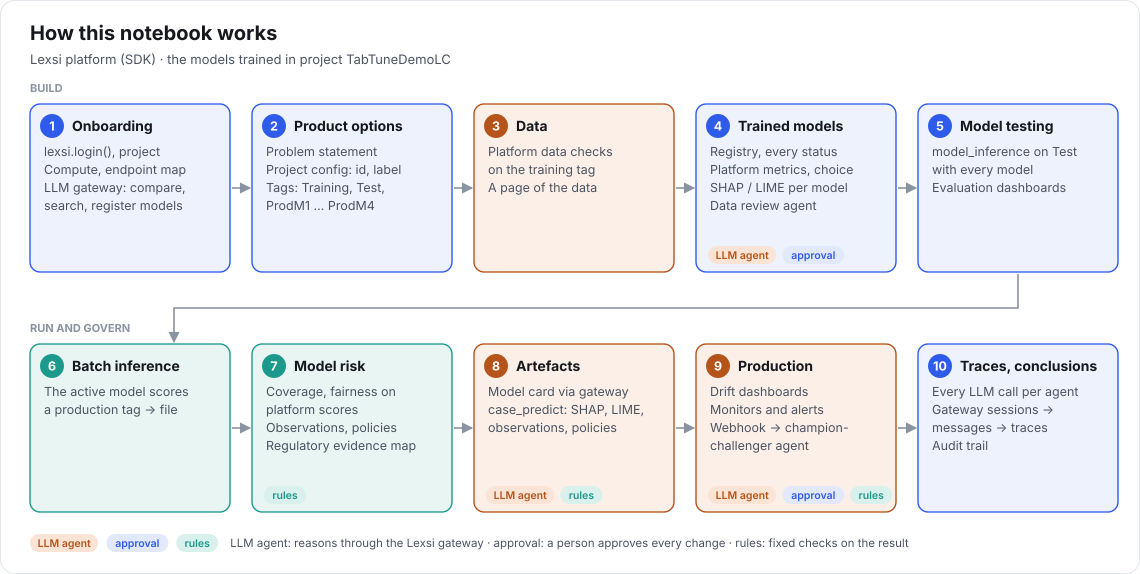

In [ ]:
# @title Diagram: how this notebook works { display-mode: "form" }
from IPython.display import SVG, display
display(SVG(data='<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 1140 574" width="1140" height="574" font-family="Inter, \'Helvetica Neue\', Helvetica, Arial, sans-serif" role="img" aria-label="How this notebook works"><defs><marker id="arr" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 z" fill="#8A93A0"/></marker></defs><rect x="0.5" y="0.5" width="1139" height="573" rx="14" fill="#FFFFFF" stroke="#E3E6EB"/><text x="30" y="40" font-size="20" fill="#16181D" font-weight="700" text-anchor="start">How this notebook works</text><text x="30" y="64" font-size="13" fill="#4A5260" font-weight="400" text-anchor="start">Lexsi platform (SDK) · the models trained in project TabTuneDemoLC</text><text x="30" y="92" font-size="11" fill="#8A93A0" font-weight="700" text-anchor="start">BUILD</text><text x="30" y="332" font-size="11" fill="#8A93A0" font-weight="700" text-anchor="start">RUN AND GOVERN</text><rect x="30" y="104" width="200" height="168" rx="10" fill="#EEF2FD" stroke="#2F5BEA" stroke-width="1.4"/><circle cx="52" cy="126" r="12" fill="#2F5BEA"/><text x="52" y="130.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">1</text><text x="72" y="131" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Onboarding</text><text x="44" y="156" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">lexsi.login(), project</text><text x="44" y="174" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Compute, endpoint map</text><text x="44" y="192" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">LLM gateway: compare,</text><text x="44" y="210" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">search, register models</text><path d="M232,188.0 L250,188.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="252" y="104" width="200" height="168" rx="10" fill="#EEF2FD" stroke="#2F5BEA" stroke-width="1.4"/><circle cx="274" cy="126" r="12" fill="#2F5BEA"/><text x="274" y="130.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">2</text><text x="294" y="131" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Product options</text><text x="266" y="156" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Problem statement</text><text x="266" y="174" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Project config: id, label</text><text x="266" y="192" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Tags: Training, Test,</text><text x="266" y="210" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">ProdM1 … ProdM4</text><path d="M454,188.0 L472,188.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="474" y="104" width="200" height="168" rx="10" fill="#FBEFE8" stroke="#B4541A" stroke-width="1.4"/><circle cx="496" cy="126" r="12" fill="#B4541A"/><text x="496" y="130.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">3</text><text x="516" y="131" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Data</text><text x="488" y="156" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Platform data checks</text><text x="488" y="174" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">on the training tag</text><text x="488" y="192" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">A page of the data</text><path d="M676,188.0 L694,188.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="696" y="104" width="200" height="168" rx="10" fill="#EEF2FD" stroke="#2F5BEA" stroke-width="1.4"/><circle cx="718" cy="126" r="12" fill="#2F5BEA"/><text x="718" y="130.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">4</text><text x="738" y="131" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Trained models</text><text x="710" y="156" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Registry, every status</text><text x="710" y="174" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Platform metrics, choice</text><text x="710" y="192" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">SHAP / LIME per model</text><text x="710" y="210" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Data review agent</text><rect x="708" y="246" width="68" height="18" rx="9" fill="#FBE3D5"/><text x="742.2" y="259" font-size="10.5" fill="#B4541A" font-weight="600" text-anchor="middle">LLM agent</text><rect x="782.4" y="246" width="62" height="18" rx="9" fill="#E2E9FC"/><text x="813.3" y="259" font-size="10.5" fill="#2F5BEA" font-weight="600" text-anchor="middle">approval</text><path d="M898,188.0 L916,188.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="918" y="104" width="200" height="168" rx="10" fill="#EEF2FD" stroke="#2F5BEA" stroke-width="1.4"/><circle cx="940" cy="126" r="12" fill="#2F5BEA"/><text x="940" y="130.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">5</text><text x="960" y="131" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Model testing</text><text x="932" y="156" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">model_inference on Test</text><text x="932" y="174" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">with every model</text><text x="932" y="192" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Evaluation dashboards</text><rect x="30" y="344" width="200" height="168" rx="10" fill="#E8F5F3" stroke="#1B998B" stroke-width="1.4"/><circle cx="52" cy="366" r="12" fill="#1B998B"/><text x="52" y="370.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">6</text><text x="72" y="371" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Batch inference</text><text x="44" y="396" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">The active model scores</text><text x="44" y="414" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">a production tag → file</text><path d="M232,428.0 L250,428.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="252" y="344" width="200" height="168" rx="10" fill="#E8F5F3" stroke="#1B998B" stroke-width="1.4"/><circle cx="274" cy="366" r="12" fill="#1B998B"/><text x="274" y="370.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">7</text><text x="294" y="371" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Model risk</text><text x="266" y="396" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Coverage, fairness on</text><text x="266" y="414" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">platform scores</text><text x="266" y="432" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Observations, policies</text><text x="266" y="450" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Regulatory evidence map</text><rect x="264" y="486" width="42" height="18" rx="9" fill="#D9F0EC"/><text x="285.0" y="499" font-size="10.5" fill="#1B998B" font-weight="600" text-anchor="middle">rules</text><path d="M454,428.0 L472,428.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="474" y="344" width="200" height="168" rx="10" fill="#FBEFE8" stroke="#B4541A" stroke-width="1.4"/><circle cx="496" cy="366" r="12" fill="#B4541A"/><text x="496" y="370.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">8</text><text x="516" y="371" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Artefacts</text><text x="488" y="396" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Model card via gateway</text><text x="488" y="414" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">case_predict: SHAP, LIME,</text><text x="488" y="432" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">observations, policies</text><rect x="486" y="486" width="68" height="18" rx="9" fill="#FBE3D5"/><text x="520.2" y="499" font-size="10.5" fill="#B4541A" font-weight="600" text-anchor="middle">LLM agent</text><rect x="560.4" y="486" width="42" height="18" rx="9" fill="#D9F0EC"/><text x="581.4" y="499" font-size="10.5" fill="#1B998B" font-weight="600" text-anchor="middle">rules</text><path d="M676,428.0 L694,428.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="696" y="344" width="200" height="168" rx="10" fill="#FBEFE8" stroke="#B4541A" stroke-width="1.4"/><circle cx="718" cy="366" r="12" fill="#B4541A"/><text x="718" y="370.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">9</text><text x="738" y="371" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Production</text><text x="710" y="396" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Drift dashboards</text><text x="710" y="414" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Monitors and alerts</text><text x="710" y="432" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Webhook → champion-</text><text x="710" y="450" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">challenger agent</text><rect x="708" y="486" width="68" height="18" rx="9" fill="#FBE3D5"/><text x="742.2" y="499" font-size="10.5" fill="#B4541A" font-weight="600" text-anchor="middle">LLM agent</text><rect x="782.4" y="486" width="62" height="18" rx="9" fill="#E2E9FC"/><text x="813.3" y="499" font-size="10.5" fill="#2F5BEA" font-weight="600" text-anchor="middle">approval</text><rect x="850.1999999999999" y="486" width="42" height="18" rx="9" fill="#D9F0EC"/><text x="871.1999999999999" y="499" font-size="10.5" fill="#1B998B" font-weight="600" text-anchor="middle">rules</text><path d="M898,428.0 L916,428.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="918" y="344" width="200" height="168" rx="10" fill="#EEF2FD" stroke="#2F5BEA" stroke-width="1.4"/><circle cx="940" cy="366" r="12" fill="#2F5BEA"/><text x="940" y="370.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">10</text><text x="960" y="371" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Traces, conclusions</text><text x="932" y="396" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Every LLM call per agent</text><text x="932" y="414" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Gateway sessions →</text><text x="932" y="432" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">messages → traces</text><text x="932" y="450" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Audit trail</text><path d="M1018.0,274 L1018.0,308 L174.0,308 L174.0,342" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="30" y="534" width="68" height="18" rx="9" fill="#FBE3D5"/><text x="64.2" y="547" font-size="10.5" fill="#B4541A" font-weight="600" text-anchor="middle">LLM agent</text><rect x="106.4" y="534" width="62" height="18" rx="9" fill="#E2E9FC"/><text x="137.3" y="547" font-size="10.5" fill="#2F5BEA" font-weight="600" text-anchor="middle">approval</text><rect x="176.2" y="534" width="42" height="18" rx="9" fill="#D9F0EC"/><text x="197.2" y="547" font-size="10.5" fill="#1B998B" font-weight="600" text-anchor="middle">rules</text><text x="230.2" y="547" font-size="11.5" fill="#4A5260" font-weight="400" text-anchor="start">LLM agent: reasons through the Lexsi gateway · approval: a person approves every change · rules: fixed checks on the result</text></svg>'))

# 1 · Onboarding

In [ ]:
# @title Install the Lexsi SDK (pinned) and plotting packages { display-mode: "form" }
import os, sys, subprocess
r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lexsi-sdk==0.1.69", "plotly", "ipywidgets", "httpx[http2]"], capture_output=True, text=True)
if r.returncode != 0:
    print((r.stdout + r.stderr)[-3000:]); raise RuntimeError("pip install failed; pip's message is printed above")
from importlib.metadata import version
print("lexsi-sdk", version("lexsi-sdk"))

In [ ]:
from lexsi_sdk import lexsi
lexsi.login()                      # paste your Lexsi access token when asked

In [ ]:
# @title Imports, theme, fact sheet, audit trail and approval gates { display-mode: "form" }
import json, logging, re, time, warnings
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, Markdown, HTML
import ipywidgets as W

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.max_columns", 60)

try:
    import torch
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    GPU = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "none"
except ImportError:
    DEVICE, GPU = "cpu", "none"

FAST = os.environ.get("TABTUNE_DEMO_FAST") == "1"      # tiny settings for a smoke test without a GPU
AUTO_APPROVE = True                                    # False = the agents stop and ask you to type yes / no
BLUE, ORANGE, TEAL, GREY, DARK, RED, GOLD = "#2F5BEA", "#B4541A", "#1B998B", "#9AA0A8", "#16181D", "#D7263D", "#E8C547"
PALETTE = [BLUE, ORANGE, TEAL, RED, GOLD, GREY, DARK, "#7A5CFA"]
FACTS = {}                                             # every number that reaches the model card is recorded here
AUDIT = []                                             # every agent step and human decision


def record(section, **values):
    """Store results for the model card and the conclusions."""
    FACTS.setdefault(section, {}).update({k: (round(float(v), 4) if isinstance(v, (int, float, np.floating, np.integer)) and not isinstance(v, bool) else v)
                                          for k, v in values.items()})


def audit(actor, step, finding, decision=""):
    AUDIT.append({"at": pd.Timestamp.now().strftime("%H:%M:%S"), "actor": actor, "step": step, "finding": finding, "decision": decision})
    print(f"[{actor} · {step}] {finding}" + (f"  →  {decision}" if decision else ""))


def human_gate(question, recommended=True):
    """Human-in-the-loop checkpoint. With AUTO_APPROVE the recommendation is taken and logged; otherwise you are asked."""
    if AUTO_APPROVE:
        answer = recommended
        who = "auto-approved (AUTO_APPROVE=True)"
    else:
        reply = input(f"🧑 {question}  [recommended: {'yes' if recommended else 'no'}]  yes/no: ").strip().lower()
        answer = reply.startswith("y") if reply else recommended
        who = "human reviewer"
    audit("human", "approval gate", question, f"{'APPROVED' if answer else 'REJECTED'} · {who}")
    return answer


print(f"auto-approve: {AUTO_APPROVE}")

In [ ]:
# ── Project with the trained models ───────────────────────────────────────────────────────
ORGANIZATION, WORKSPACE, PROJECT = "Lexsi Labs", "TabTunetesting", "TabTuneDemoLC"
TASK = "classification"
MODELS = ["TabICLv2_v1", "TabICLv2_distilled_v1", "OrionMSP_v1", "OrionBix_v1", "OrionMoE_v3"]     # as listed in the project; models still running join once finished
TRAIN_TAG, EVAL_TAG, PROD_PREFIX = "Training", "Test", "Prod"     # "auto" picks from the project's tags
UID_DEFAULT, TARGET_DEFAULT = "id", "TARGET"              # used only if the project config cannot be read

# ── Compute ─────────────────────────────────────────────────────────────────────────────
INFER_GPU, INFER_CPU = "T4.small", "small"                # batch scoring: GPU type for foundation models, CPU type for classic models
CASE_SERVERLESS = {"gpu": "gova-4", "cpu": "nova-2"}      # serverless types for single cases, as shown on the model cards
DASHBOARD_POD = "small"                                   # drift dashboards and monitors

# ── Choices ─────────────────────────────────────────────────────────────────────────────
SCORE_ALL_MODELS = True          # False = score only the best and the active model
PROMOTE_CHAMPION = False         # True = make the best model the active one in section 4 (after a human gate)
REQUIRE_COMMERCIAL = False       # True = only models cleared for commercial use may be chosen
RUN_SUPPORT_SET = True
N_CHALLENGERS, MAX_REVIEWS, PROMOTE_MARGIN = 2, 2, 0.002
ALERT_EMAILS = []                # addresses that receive monitor alerts; empty = no e-mail
MONITOR_PREFIX = "LC default"
POLICY_DECISION = {"decision": "input", "input": "Refer to manual review"}

# ── LLM gateway: role → (provider, model), as registered in the gateway project ─────────
LLM_PROJECT, LLM_PROJECT_ID = "demo", "demo_Z1P8OHR7RU"
LLM_WORKSPACE, LLM_CLIENT_ID = WORKSPACE, "adityatanna"
GATEWAY_MODELS = {
    "agents":      ("Open Router", "anthropic-claude-sonnet-5.5_v1"),
    "card_writer": ("Open Router", "anthropic-claude-sonnet-5.5_v1"),
}
AGENT_MAX_TOKENS, CARD_MAX_TOKENS = 4000, 32000

# ── Use case ────────────────────────────────────────────────────────────────────────────
TITLE, DATA_SOURCE, DECISION = "Lending Club · Credit Default Prediction", "Lending Club", "approve, review or decline a loan application"
POSITIVE, CLASS_NAMES = "1", ["Fully paid", "Default"]
GROUP_PREFIX, GROUP_LABEL = "home_ownership_", "home ownership"

In [ ]:
# @title Helpers: platform calls, model registry, scoring, catalogue, evaluation dashboards { display-mode: "form" }
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from contextlib import contextmanager
from IPython.display import display, Markdown

BLUE, ORANGE, TEAL, GREY, DARK, RED = "#2F5BEA", "#B4541A", "#1B998B", "#9AA0A8", "#16181D", "#D7263D"
pd.set_option("display.max_columns", 50)


def get_or_create(workspace, name, project_type):
    """Reuse a project if it exists, otherwise create it. Safe to rerun."""
    try:
        project = workspace.project(name)
        print(f"reusing project: {name}")
    except Exception:
        project = workspace.create_project(name, modality="tabular", project_type=project_type)
        print(f"created project: {name}")
    return project


def upload_once(project, csv_path, tag, config=None, compute_type=None):
    """Upload a file unless this tag already has it; set the config only on the first upload.

    Workarounds for lexsi-sdk 0.1.69, applied to the first upload only:
      1. upload_data() deletes the freshly uploaded file -> delete_file is suspended during the call.
      2. an empty pred_label is no longer sent -> pred_label="" is put back in the request.
      3. if the platform cannot read the uploaded file back, the SDK fails with "'str' object has no attribute 'get'"
         -> the platform's own message is raised instead.
      4. a file with the same name left by an earlier attempt (or a cancelled upload in the UI) is removed, and the new copy
         is uploaded under a fresh name, so the platform never reads a path that is being deleted.
    """
    import os, shutil
    try:
        files = project.files()
        existing = set(files["file_name"]) if "file_name" in files else set()
    except Exception:
        existing = set()
    name = os.path.basename(csv_path)
    has_config = project.config() != "Not Found"
    if name in existing and (has_config or config is None):
        print(f"already uploaded: {name} ({tag})")
        return
    if config is None or has_config:
        print(project.upload_data(csv_path, tag))
        return

    if name in existing:                                   # left over from a failed first upload or a cancelled UI upload
        print(f"removing the leftover {name} (the project has no configuration yet) →", project.delete_file(name))
        time.sleep(5)
        fresh = csv_path.replace(".csv", f"_{time.strftime('%H%M%S')}.csv")
        shutil.copy(csv_path, fresh)
        csv_path = fresh
        print(f"uploading as {os.path.basename(fresh)}")
    cls, api_cls = type(project), type(project.api_client)
    had_own, real_delete = "delete_file" in cls.__dict__, cls.__dict__.get("delete_file")
    real_post = api_cls.post

    def post_patched(self, uri, payload=None, *a, **k):
        if isinstance(payload, dict) and "unique_identifier" in payload and payload.get("pred_label") is None:
            payload["pred_label"] = ""
        res = real_post(self, uri, payload, *a, **k)
        if "get_Uploaded_file_info" in str(uri) and isinstance(res, dict) and not res.get("success"):
            raise RuntimeError(f"the platform could not read the uploaded file back: {res.get('details') or res.get('result')}. "
                               "If this repeats, set PROJECT to a new name in the config cell and rerun from section 1.")
        return res

    cls.delete_file = lambda self, *a, **k: "skipped"
    api_cls.post = post_patched
    try:
        print(project.upload_data(csv_path, tag, config=config, compute_type=compute_type))
    finally:
        api_cls.post = real_post
        if had_own:
            cls.delete_file = real_delete
        else:
            del cls.delete_file


@contextmanager
def tolerant_drop():
    """project.models() drops columns that some backend builds do not return."""
    orig = pd.DataFrame.drop

    def safe(self, *a, **k):
        k.setdefault("errors", "ignore")
        return orig(self, *a, **k)

    pd.DataFrame.drop = safe
    try:
        yield
    finally:
        pd.DataFrame.drop = orig


RUNS = []          # one record per training call, shown in the run log


def trained_models(project):
    with tolerant_drop():
        df = project.models()
    return df


def summary_of(project, model_name):
    try:
        return project.model_summary(model_name=model_name)
    except Exception as exc:
        print(f"no summary for {model_name}: {exc}")
        return None


def gfi(summary, method):
    """Global feature importance dict {feature: value} for 'shap' or 'lime', or {}."""
    if summary is None:
        return {}
    block = (summary.model_results or {}).get("GFI", {}) or {}
    raw = block.get(f"{method}_gfi") or {}
    out = {}
    for k, v in raw.items():
        try:
            out[k] = float(np.mean(np.abs(list(v.values())))) if isinstance(v, dict) else float(v)
        except Exception:
            pass
    return out


def support_rows(summary):
    if summary is None:
        return pd.DataFrame()
    block = ((summary.model_results or {}).get("GFI", {}) or {}).get("support_set_attribution") or {}
    return pd.DataFrame(block.get("top_support_rows", []))


def top_bar(importance, title, n=15, color=BLUE):
    s = pd.Series(importance).abs().sort_values(ascending=False).head(n)[::-1]
    fig = go.Figure(go.Bar(x=s.values, y=s.index, orientation="h", marker_color=color))
    fig.update_layout(template="plotly_white", height=36 * len(s) + 140, title=title,
                      xaxis_title="mean |attribution|", margin=dict(l=10, r=10, t=60, b=40))
    return fig

def model_names(project):
    try:
        return set(trained_models(project)["model_name"].astype(str))
    except Exception:
        return set()


def train(project, label, **kwargs):
    """train_model with timing, a status line, and the exact name of the model it created."""
    before, t0 = model_names(project), time.time()
    try:
        project.train_model(**kwargs)
        status = "ok"
    except Exception as exc:
        status = f"failed: {str(exc)[:160]}"
        xai = (kwargs.get("data_config") or {}).get("xai_method", [])
        if "support_set" in xai and "not allowed" in str(exc):
            print(f"↺ {label}: support set is not enabled for this account; retrying with SHAP and LIME")
            kwargs["data_config"] = {**kwargs["data_config"], "xai_method": [m for m in xai if m != "support_set"]}
            return train(project, label, **kwargs)
    new = sorted(model_names(project) - before)
    RUNS.append({"run": label, "strategy": kwargs.get("training_strategy"), "model": str(kwargs.get("model")),
                 "created": ", ".join(new), "status": status, "minutes": round((time.time() - t0) / 60, 1)})
    print(("✅ " if status == "ok" else "❌ ") + f"{label} → {', '.join(new) or '-'}: {status} ({RUNS[-1]['minutes']} min)")
    return new[-1] if (status == "ok" and new) else None


def base_data_config(xai):
    return {"tags": ["Training"], "test_tags": ["Test"], "feature_exclude": FEATURE_EXCLUDE,
            "xai_method": xai, "lime_explainability_iterations": LIME_ITERATIONS}


def model_config_for(models):
    models = [models] if isinstance(models, str) else list(models)
    return {"tabpfn_token": TABPFN_TOKEN} if "TabPFNv3" in models and TABPFN_TOKEN else None


def eval_metrics(summary):
    return dict((summary.model_results or {}).get("evalution_metrics", {}) or {}) if summary else {}


def modelling_info(summary):
    return dict((summary.model_results or {}).get("modelling_info", {}) or {}) if summary else {}


def features_used(summary):
    return list((summary.model_results or {}).get("feature_actual_used", []) or []) if summary else []


def ensure_inference(project, model_name):
    """Make `model_name` the active model and enable it for inference."""
    project.activate_model(model_name)
    try:
        project.update_inference_model_status(model_name, True)
    except Exception:
        pass


def case_attributions(case, kind="shap", positive="1"):
    """Signed per-feature attribution dict from a case, picking the positive class when nested."""
    raw = getattr(case, f"{kind}_feature_importance", {}) or {}
    if raw and isinstance(next(iter(raw.values())), dict):
        key = positive if positive in raw else list(raw)[-1]
        raw = raw[key]
    out = {}
    for k, v in raw.items():
        try:
            out[k] = float(v)
        except Exception:
            pass
    return out


def signed_bar(attr, title, n=12):
    s = pd.Series(attr)
    s = s.reindex(s.abs().sort_values(ascending=False).index).head(n)[::-1]
    fig = go.Figure(go.Bar(x=s.values, y=s.index, orientation="h",
                           marker_color=[RED if v > 0 else BLUE for v in s.values]))
    fig.update_layout(template="plotly_white", height=34 * len(s) + 150, title=title,
                      xaxis_title="contribution (red pushes the prediction up)", margin=dict(l=10, r=10, t=60, b=40))
    return fig

from sklearn import metrics as skm


def prediction_columns(result, uploaded):
    """Columns the platform added to the uploaded tag (prediction, probabilities, ...)."""
    return [c for c in result.columns if c not in set(uploaded.columns)]


def positive_proba(result, added, positive="1"):
    """Best guess at the positive-class probability column among the added columns."""
    numeric = [c for c in added if pd.api.types.is_numeric_dtype(result[c])
               and result[c].between(0, 1).all() and result[c].nunique() > 2]
    ranked = sorted(numeric, key=lambda c: (str(positive) not in c.split("_")[-1] and not c.endswith(str(positive)),
                                            "prob" not in c.lower() and "score" not in c.lower()))
    return ranked[0] if ranked else None


def predicted_label(result, added):
    cands = [c for c in added if result[c].nunique() <= 20]
    named = [c for c in cands if "pred" in c.lower()]
    return (named or cands or [None])[0]

def classification_dashboard(y_true, p, title, threshold=0.5):
    """ROC, precision-recall, calibration, score distribution, gains and confusion matrix."""
    y = np.asarray(y_true).astype(int)
    fpr, tpr, _ = skm.roc_curve(y, p)
    prec, rec, _ = skm.precision_recall_curve(y, p)
    auc, ap = skm.roc_auc_score(y, p), skm.average_precision_score(y, p)
    bins = pd.qcut(p, 10, labels=False, duplicates="drop")
    cal = pd.DataFrame({"p": p, "y": y, "bin": bins}).groupby("bin").mean()
    order = np.argsort(-p)
    gains = np.cumsum(y[order]) / y.sum()
    share = np.arange(1, len(y) + 1) / len(y)
    pred = (p >= threshold).astype(int)
    cm = skm.confusion_matrix(y, pred)
    fig = make_subplots(rows=2, cols=3, vertical_spacing=0.16, horizontal_spacing=0.08,
                        subplot_titles=(f"ROC · AUC {auc:.3f}", f"Precision–recall · AP {ap:.3f}", "Calibration",
                                        "Score distribution by outcome", "Cumulative gains",
                                        f"Confusion matrix @ {threshold:.2f}"))
    fig.add_trace(go.Scatter(x=fpr, y=tpr, line=dict(color=BLUE, width=3), name="ROC"), 1, 1)
    fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], line=dict(color=GREY, dash="dot"), showlegend=False), 1, 1)
    fig.add_trace(go.Scatter(x=rec, y=prec, line=dict(color=ORANGE, width=3), name="PR"), 1, 2)
    fig.add_hline(y=y.mean(), line_dash="dot", line_color=GREY, row=1, col=2)
    fig.add_trace(go.Scatter(x=cal.p, y=cal.y, mode="lines+markers", line=dict(color=TEAL, width=3), name="observed"), 1, 3)
    fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], line=dict(color=GREY, dash="dot"), showlegend=False), 1, 3)
    for cls, col in ((0, BLUE), (1, RED)):
        fig.add_trace(go.Histogram(x=p[y == cls], nbinsx=30, opacity=0.6, marker_color=col,
                                   name=CLASS_NAMES[cls], histnorm="probability"), 2, 1)
    fig.add_trace(go.Scatter(x=share, y=gains, line=dict(color=BLUE, width=3), name="model"), 2, 2)
    fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], line=dict(color=GREY, dash="dot"), name="random"), 2, 2)
    fig.add_trace(go.Heatmap(z=cm[::-1], x=[f"pred {c}" for c in CLASS_NAMES], y=[f"true {c}" for c in CLASS_NAMES[::-1]],
                             text=cm[::-1], texttemplate="%{text}", colorscale="Blues", showscale=False), 2, 3)
    fig.update_layout(template="plotly_white", height=760, title=title, barmode="overlay",
                      legend=dict(orientation="h", y=-0.08))
    fig.update_xaxes(title_text="false positive rate", row=1, col=1); fig.update_yaxes(title_text="true positive rate", row=1, col=1)
    fig.update_xaxes(title_text="recall", row=1, col=2); fig.update_xaxes(title_text="mean predicted", row=1, col=3)
    fig.update_xaxes(title_text="share of applicants reviewed", row=2, col=2)
    fig.show()
    return {"roc_auc": auc, "avg_precision": ap, "brier": skm.brier_score_loss(y, p),
            "f1@thr": skm.f1_score(y, pred), "recall@thr": skm.recall_score(y, pred),
            "precision@thr": skm.precision_score(y, pred, zero_division=0)}

CATALOGUE = pd.DataFrame([
    # model,          classification, regression, support_set, shap_regression, commercial,  note
    ("OrionMoE",      True,  False, False, False, "yes",        "Lexsi mixture-of-experts, inference only"),
    ("OrionMSP",      True,  False, True,  False, "yes",        "Lexsi multi-scale sparse attention"),
    ("OrionBix",      True,  False, True,  False, "yes",        "Lexsi bi-axial attention"),
    ("OrionMSPv1.5",  True,  False, False, False, "yes",        "Lexsi"),
    ("TabICL",        True,  False, True,  False, "yes",        ""),
    ("TabICLv2",      True,  True,  False, True,  "yes",        ""),
    ("TabPFN",        True,  True,  False, True,  "unverified", ""),
    ("TabPFNv26",     True,  True,  True,  True,  "unverified", ""),
    ("TabPFNv3",      True,  True,  True,  True,  "no",         "needs a tabpfn_token"),
    ("TabDPT",        True,  True,  False, True,  "unverified", ""),
    ("Mitra",         True,  True,  False, False, "yes",        "no predict_proba"),
    ("ContextTab",    True,  True,  False, False, "no",         ""),
    ("Limix",         True,  True,  True,  True,  "no",         ""),
    ("TabFM",         True,  True,  False, False, "no",         "Google"),
    ("EXAONETabular", True,  False, False, False, "no",         "LG AI Research"),
    ("ILTM",          True,  True,  False, False, "yes",        ""),
    ("XRFM",          True,  True,  False, True,  "yes",        "trains from scratch"),
], columns=["model", "classification", "regression", "support_set", "shap_regression", "commercial", "note"]).set_index("model")


def xai_for(model, task):
    """Explainability methods the backend accepts for a simple build of `model`."""
    cap = CATALOGUE.loc[model]
    if task == "regression":
        return ["shap", "lime"] if cap.shap_regression else ["lime"]
    methods = ["shap", "lime"]
    if cap.support_set and RUN_SUPPORT_SET:
        methods.append("support_set")
    return methods

def attempt(label, fn, default=None, show=True):
    """Run one platform call; on failure print the platform's message and carry on, so one failing call never stops the demo."""
    t0 = time.time()
    try:
        out = fn()
        if isinstance(out, Exception):                     # some SDK calls return the error instead of raising it
            raise out
        if show:
            print(f"✅ {label} ({time.time() - t0:.1f}s)" + (f" → {out}" if isinstance(out, str) and len(out) < 120 else ""))
        return out
    except Exception as exc:
        print(f"⚠️ {label}: {str(exc)[:300]}")
        return default


def as_frame(obj):
    """Platform list calls return a DataFrame, or a message string when there is nothing yet."""
    return obj if isinstance(obj, pd.DataFrame) else pd.DataFrame()

from lexsi_sdk.common.xai_uris import GET_MODELS_URI
CLASSIC = {"XGBoost", "LGBoost", "LightGBM", "CatBoost", "RandomForest", "SGD", "LogisticRegression", "LinearRegression", "GaussianNaiveBayes"}
READY = {"active", "inactive", "staged", "completed"}


def all_models(project):
    """Every model in the project with its status. project.models() hides inactive models, so the registry endpoint is read directly."""
    try:
        res = project.api_client.get(f"{GET_MODELS_URI}?project_name={project.project_name}")
        df = pd.DataFrame(res["details"]["staged"])
    except Exception:
        df = trained_models(project)
    keep = [c for c in ("model_name", "status", "tabular_model_type", "instance_type", "inference_status", "created_at", "updated_at") if c in df]
    return df[keep].reset_index(drop=True) if len(df) else pd.DataFrame(columns=["model_name", "status"])


def compute_for(model):
    return INFER_CPU if model.split("_")[0] in CLASSIC else INFER_GPU


def serverless_for(model):
    return CASE_SERVERLESS["cpu" if model.split("_")[0] in CLASSIC else "gpu"]


SCORE_CACHE = {}


def score_tag(tag, model):
    """Scores of `model` on `tag`. Reuses an inference the project already holds; otherwise runs one on platform compute.
    Inactive models can be scored once their inference status is on; the SDK's own check only lists active models, so it is widened for the call."""
    if (tag, model) in SCORE_CACHE:
        return SCORE_CACHE[(tag, model)]
    cached = f"{tag}_{model}_Inference"
    if cached in ALL_TAGS:
        out = attempt(f"download existing inference {cached}", lambda: project.get_tag_data(cached), show=False)
        if isinstance(out, pd.DataFrame) and len(out):
            SCORE_CACHE[(tag, model)] = with_truth(out, tag)
            return SCORE_CACHE[(tag, model)]
    attempt(f"enable inference for {model}", lambda: project.update_inference_model_status(model, True), show=False)
    cls, orig = type(project), type(project).models
    cls.models = lambda self: all_models(self)
    try:
        t0 = time.time()
        out = project.model_inference(tag=tag, model_name=model, compute_type=compute_for(model))
        print(f"✅ {model} scored {tag} on {compute_for(model)} ({time.time() - t0:.0f}s, {len(out):,} rows)")
    finally:
        cls.models = orig
    SCORE_CACHE[(tag, model)] = with_truth(out, tag)
    return SCORE_CACHE[(tag, model)]


def with_truth(df, tag):
    """Make sure the scored frame carries the true label (merge it from the tag's data if the output does not)."""
    if TARGET_COL in df:
        return df
    truth = attempt(f"labels of {tag}", lambda: project.get_tag_data(tag)[[UID, TARGET_COL]], show=False)
    return df.merge(truth, on=UID, how="left") if isinstance(truth, pd.DataFrame) else df


PRED = "pred_proba_AutoML" if TASK == "classification" else "Predicted_value_AutoML"


def y_and_score(df):
    s = pd.to_numeric(df[PRED], errors="coerce").to_numpy()
    if TASK == "classification":
        return (df[TARGET_COL].astype(str).str.replace(r"\.0$", "", regex=True) == POSITIVE).astype(int).to_numpy(), s
    return pd.to_numeric(df[TARGET_COL], errors="coerce").to_numpy(), s


def local_metric(df):
    y_, s_ = y_and_score(df)
    ok = ~(np.isnan(s_) | np.isnan(y_.astype(float)))
    return float(skm.roc_auc_score(y_[ok], s_[ok]) if TASK == "classification" else skm.r2_score(y_[ok], s_[ok]))

In [ ]:
organization = lexsi.organization(ORGANIZATION)
workspace = organization.workspace(WORKSPACE)
project = workspace.project(PROJECT)          # the project that already holds the data and the trained models
print(project.project_name)

In [ ]:
from lexsi_sdk.common.xai_uris import AVAILABLE_BATCH_SERVERS_URI, AVAILABLE_CUSTOM_SERVERS_URI

def _servers(uri):
    res = attempt(uri, lambda: project.api_client.get(uri), default=[], show=False) or []
    items = res.get("details") or [] if isinstance(res, dict) else res          # one endpoint wraps the list, the other does not
    return [s if isinstance(s, dict) else {"instance_name": str(s)} for s in items]

cpu_batch = [s.get("instance_name") for s in _servers(AVAILABLE_BATCH_SERVERS_URI)]
custom = _servers(AVAILABLE_CUSTOM_SERVERS_URI)
gpu_types = [s.get("instance_name") for s in custom if "gpu" in s]               # same rule the SDK uses
print("CPU batch types:", ", ".join(map(str, cpu_batch)) or "-")
print("GPU servers:    ", ", ".join(map(str, gpu_types)) or "-", "(for dedicated servers; batch scoring uses the T4 / A10G types)")
GPU_BATCH = ["T4.small", "T4.xsmall", "T4.2xsmall", "T4.3xsmall", "A10G.medium", "A10G.xmedium", "A10G.2xmedium", "A10G.3xmedium"]   # what batch scoring accepts
if INFER_GPU not in GPU_BATCH:
    print(f"⚠️ INFER_GPU = '{INFER_GPU}' is not a GPU batch type → using 'T4.small'")
    INFER_GPU = "T4.small"
if cpu_batch and INFER_CPU not in cpu_batch:
    print(f"⚠️ INFER_CPU = '{INFER_CPU}' is not offered here → using '{cpu_batch[0]}'")
    INFER_CPU = cpu_batch[0]
print(f"scoring compute → foundation models: {INFER_GPU} · classic models: {INFER_CPU}")

## 1.2 Endpoint map
Every step is one SDK call, and every SDK call is one REST endpoint under `https://api.lexsi.ai`.

In [ ]:
# @title SDK call → REST endpoint { display-mode: "form" }
ENDPOINT_MAP = pd.DataFrame([
    ("Sign in",                    "lexsi.login()",                                         "POST v2/access-token/authorize"),
    ("Project",                    "workspace.create_project(...) · workspace.project(...)", "workspace and project management"),
    ("Data checks",                "project.data_observations(tag) · data_warnings(tag)",    "POST v2/project/data_summary"),
    ("Model registry",             "registry with every status · activate_model(name)",     "GET v2/ai-models/get_all_models · POST v2/ai-models/update_active_model"),
    ("Project config and tags",    "project.config() · tags() · tag_data(tag)",            "v2/project/get_project_config · get_all_available_tags_info"),
    ("Inference status",           "project.update_inference_model_status(name, True)",    "POST v2/ai-models/update_inference_model_status"),
    ("Model summary, global XAI",  "project.model_summary(model_name)",                      "v2/project/get_model_perfermance"),
    ("Batch inference",            "project.model_inference(tag=, model_name=, compute_type=)", "POST v2/ai-models/run_model_on_data"),
    ("Single case + explanations", "project.case_predict(unique_identifier=, xai=, risk_policies=True)", "v2/ai-models/get_case_info_components"),
    ("Observations",               "project.create_observation(...) · observations()",       "POST v2/observations/create_observation"),
    ("Policies",                   "project.create_policy(...) · policies()",                "POST v2/policies/create_policy"),
    ("Drift dashboards",           "project.get_data_drift_dashboard(payload) · get_target_drift_dashboard(payload)", "POST v2/dashboards/generate_dashboard?type=..."),
    ("Monitors",                   "project.create_monitor(payload) · monitors()",           "POST v2/triggers/update_triggers"),
    ("Alerts",                     "project.alerts() · get_alert_details(id)",               "POST v2/triggers/get_executed_triggers"),
    ("LLM gateway",                "text_project.chat_completion(model=, provider=, messages=, session_id=)", "POST gateway/v1/chat/completions"),
    ("Gateway model catalogue",    "text_project.search_text_models(provider) · initialize_text_model(...)", "model search and registration"),
    ("Agent traces",               "text_project.sessions() · messages(session_id) · traces(trace_id)", "GET sessions/get_sessions · sessions/get_session_messages · traces/get_traces"),
], columns=["Step", "SDK call", "REST endpoint"])
display(ENDPOINT_MAP.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"})
        .set_caption("Every platform step in this notebook: the SDK call and the endpoint behind it"))

## 1.3 The LLM gateway: one endpoint, many models
`POST /gateway/v1/chat/completions` is one OpenAI-compatible endpoint in front of every provider registered in a Lexsi text project. The gateway applies the project's guardrails and stores every call as a **session message with a trace**.

**The agents in this notebook are LLM-reviewed.** Deterministic code computes the evidence (platform metrics, scores, drift); the LLM reads it, decides and explains in plain English; a human gate confirms any change. Three agents use the gateway: the **data review agent** (section 4), the **champion-challenger agent** (section 9) and the **model-card writer** (section 8). The model for each role is set in `GATEWAY_MODELS`.

In [ ]:
# @title Gateway client, agent reviewer and trace log { display-mode: "form" }
import uuid, httpx
try:
    import h2
    HTTP2 = True
except ImportError:
    HTTP2 = False

AGENT_TRACE = []                                   # one row per LLM call made by any agent in this notebook
_SESSION = {"id": str(uuid.uuid4()), "use": True}  # all agent calls share one gateway session, so their traces sit together
LEXSI_BASE = os.environ.get("LEXSI_GATEWAY_BASE", "https://api.lexsi.ai/gateway/v1")


def _secret(name):
    try:
        from google.colab import userdata
        v = userdata.get(name)
        if v:
            return v
    except Exception:
        pass
    return os.environ.get(name)


def connect_gateway():
    """Open the Lexsi text project that fronts the LLM gateway. Returns None if it cannot be reached through the SDK."""
    for ws_name in dict.fromkeys([LLM_WORKSPACE, WORKSPACE]):
        try:
            tp = organization.workspace(ws_name).project(LLM_PROJECT)
            print(f"gateway project: {LLM_PROJECT} (workspace {ws_name}) · project id {getattr(tp, 'project_name', LLM_PROJECT_ID)}")
            return tp
        except Exception as exc:
            print(f"text project '{LLM_PROJECT}' not found in workspace '{ws_name}': {str(exc)[:120]}")
    if _secret("LEXSI_API_TOKEN"):
        print("→ using the gateway REST endpoint directly with the LEXSI_API_TOKEN secret")
    else:
        print("→ no gateway available: agents fall back to their rule defaults and the model card to the template writer")
    return None


def gateway_ready():
    return text_project is not None or bool(_secret("LEXSI_API_TOKEN"))


def _chat_sdk(provider, model, messages, max_tokens):
    kw = dict(model=model, messages=messages, provider=provider, max_tokens=max_tokens)
    if _SESSION["use"]:
        try:
            return text_project.chat_completion(session_id=_SESSION["id"], **kw)
        except Exception as exc:
            if "session" not in str(exc).lower():
                raise
            _SESSION["use"] = False                           # the gateway did not accept a client-side session id
    return text_project.chat_completion(**kw)


def _chat_rest(provider, model, messages, max_tokens):
    payload = {"provider": provider, "model": model, "project_name": LLM_PROJECT_ID, "client_id": LLM_CLIENT_ID,
               "max_tokens": max_tokens, "messages": messages, "stream": False}
    post = lambda body: client.post(f"{LEXSI_BASE}/chat/completions", json=body,
                                    headers={"x-api-token": _secret("LEXSI_API_TOKEN"), "Content-Type": "application/json"})
    with httpx.Client(http2=HTTP2, timeout=httpx.Timeout(900, connect=30)) as client:
        r = post({**payload, "session_id": _SESSION["id"]}) if _SESSION["use"] else post(payload)
        if r.status_code in (400, 422) and _SESSION["use"]:
            _SESSION["use"] = False                           # this gateway route does not take a client-side session id
            r = post(payload)
    if r.status_code != 200:
        raise RuntimeError(f"gateway returned {r.status_code}: {r.text[:300]}")
    return r.json()


def _chat(provider, model, messages, max_tokens):
    """One chat completion through the Lexsi gateway: the SDK route first, the REST route (API token) as the fallback."""
    if text_project is not None and _SESSION.get("sdk", True):
        try:
            return _chat_sdk(provider, model, messages, max_tokens), "sdk"
        except Exception as exc:
            if not _secret("LEXSI_API_TOKEN"):
                raise
            _SESSION["sdk"] = False
            print(f"gateway call through the SDK failed ({str(exc)[:160]}) → using the REST endpoint with the API token from here on")
    return _chat_rest(provider, model, messages, max_tokens), "rest"


def llm_call(role, messages, max_tokens=2000, agent=None, step=None):
    """Call the model assigned to `role` in GATEWAY_MODELS and log the call."""
    provider, model = GATEWAY_MODELS[role]
    t0 = time.time()
    body, via = _chat(provider, model, messages, max_tokens)
    if not isinstance(body, dict) or not body.get("choices"):
        raise RuntimeError(f"no answer from the gateway: {str(body)[:300]}")          # e.g. blocked by a guardrail
    ch = body["choices"][0]; msg = ch.get("message") or {}
    text = msg.get("content") or ""
    if isinstance(text, list):
        text = "".join(b.get("text", "") for b in text if isinstance(b, dict))
    usage = body.get("usage") or {}
    out = {"text": text, "finish_reason": str(ch.get("finish_reason")), "seconds": round(time.time() - t0, 1), "provider": provider, "model": model,
           "via": via, "input_tokens": usage.get("prompt_tokens") or 0, "output_tokens": usage.get("completion_tokens") or 0,
           "reasoning": msg.get("reasoning") or msg.get("reasoning_content") or ""}
    AGENT_TRACE.append({"at": pd.Timestamp.now().strftime("%H:%M:%S"), "agent": agent or role, "step": step or "", "provider": provider, "model": model,
                        "via": via, "seconds": out["seconds"], "input_tokens": out["input_tokens"], "output_tokens": out["output_tokens"],
                        "finish_reason": out["finish_reason"], "decision": "", "rationale": ""})
    return out


AGENT_SYSTEM = ("You are the {agent} in a bank's model pipeline. You review ONE proposed action at a time. The evidence was computed by "
                "deterministic checks; do not invent numbers. Reply with JSON only, no other text: "
                '{{"decision": "approve" or "reject", "rationale": "<one or two plain-English sentences that cite the evidence>"}}. '
                "Approve when the evidence supports the action and the action is reversible or reviewed by a human; reject when the "
                "evidence is weak or the action would remove information the model legitimately needs.")


def agent_llm(agent, step, evidence, default="approve", mandatory=False):
    """Ask the agent's LLM for a decision on one step. Rules stay in charge of mandatory steps; the LLM explains them."""
    if not gateway_ready():
        return {"decision": default, "rationale": "rule default (no LLM gateway configured)", "source": "rules"}
    note = " This step is mandated by policy: decide 'approve' and explain why the rule exists." if mandatory else ""
    try:
        res = llm_call("agents", [{"role": "system", "content": AGENT_SYSTEM.format(agent=agent) + note},
                                  {"role": "user", "content": json.dumps({"step": step, **evidence}, default=str)[:6000]}],
                       max_tokens=AGENT_MAX_TOKENS, agent=agent, step=step)
        m = re.search(r"\{.*\}", res["text"], flags=re.S)
        verdict = json.loads(m.group(0)) if m else {}
        decision = str(verdict.get("decision", "")).lower()
        if decision not in ("approve", "reject"):
            raise ValueError(f"unreadable answer: {res['text'][:120]}")
        if mandatory:
            decision = "approve"
        out = {"decision": decision, "rationale": str(verdict.get("rationale", ""))[:400], "source": f"{res['provider']} · {res['model']}"}
        AGENT_TRACE[-1].update(decision=decision, rationale=out["rationale"])
    except Exception as exc:
        out = {"decision": default, "rationale": f"rule default (LLM call failed: {str(exc)[:120]})", "source": "rules"}
    audit(agent, f"{step} · LLM review", out["rationale"], f"{out['decision'].upper()} · {out['source']}")
    return out

def compare_models(question, roles=None, max_tokens=600):
    """Send one prompt to every distinct model configured in GATEWAY_MODELS and compare the answers."""
    if not gateway_ready():
        return pd.DataFrame([{"provider": p, "model": m, "answer": "not called: no gateway configured"} for p, m in dict.fromkeys(GATEWAY_MODELS.values())])
    rows, seen = [], set()
    for role in roles or GATEWAY_MODELS:
        key = GATEWAY_MODELS[role]
        if key in seen:
            continue
        seen.add(key)
        try:
            r = llm_call(role, [{"role": "user", "content": question}], max_tokens=max_tokens, agent="gateway check", step="model comparison")
            rows.append({"provider": key[0], "model": key[1], "seconds": r["seconds"], "input_tokens": r["input_tokens"],
                         "output_tokens": r["output_tokens"], "answer": r["text"].strip()[:300]})
        except Exception as exc:
            rows.append({"provider": key[0], "model": key[1], "answer": f"failed: {str(exc)[:200]}"})
    return pd.DataFrame(rows)

REVIEW_SYSTEM = ("You are the {agent} in a bank's model-risk team. You receive aggregate evidence about a credit model: the platform's data "
                 "observations and warnings and the share of the model's attribution carried by each top feature. Flag features a reviewer "
                 "should look at: possible target leakage (a feature that restates or is computed from the target, or is only known after the "
                 "decision), features with data-quality warnings, or a driver with an outsized share. Do not invent numbers. Reply with JSON only: "
                 '{{"flags": [{{"feature": "...", "concern": "...", "suggested_action": "..."}}], "summary": "<two plain-English sentences>"}}')


def review_llm(agent, step, evidence):
    """One LLM review through the gateway, logged like every other agent call."""
    if not gateway_ready():
        return {"summary": "no LLM gateway configured: no review"}
    try:
        res = llm_call("agents", [{"role": "system", "content": REVIEW_SYSTEM.format(agent=agent)},
                                  {"role": "user", "content": json.dumps(evidence, default=str)[:12000]}], max_tokens=AGENT_MAX_TOKENS, agent=agent, step=step)
        m = re.search(r"\{.*\}", res["text"], flags=re.S)
        out = json.loads(m.group(0)) if m else {"summary": res["text"][:400]}
        AGENT_TRACE[-1].update(decision=f"{len(out.get('flags', []))} flag(s)", rationale=str(out.get("summary", ""))[:400])
        audit(agent, step, str(out.get("summary", ""))[:300], f"{len(out.get('flags', []))} FLAG(S)")
        return out
    except Exception as exc:
        print(f"⚠️ {agent}: {str(exc)[:200]}")
        return {"summary": f"review failed: {str(exc)[:120]}"}

In [ ]:
text_project = connect_gateway()                     # the Lexsi text project that fronts the gateway

In [ ]:
compare_models("In one sentence: what does the population stability index (PSI) tell a credit-risk team?")

# 2 · Product options

## Problem statement
**Will this borrower default?** A retail lender scores each loan application for the probability of default, so that risky applications are reviewed, priced or declined before money goes out.

## The project on the platform
The data was uploaded and the models trained in project `TabTuneDemoLC` before this notebook. The next cell reads the project's configuration (unique identifier, true label) and its **tags**: the training tag, the test tag the platform scored the models on, and the production tags used for monitoring.

In [ ]:
# @title Project configuration, tags and files { display-mode: "form" }
cfg = attempt("project configuration", lambda: project.config(), default={}) or {}
cfg = cfg if isinstance(cfg, dict) else {}
UID, TARGET_COL = cfg.get("unique_identifier") or UID_DEFAULT, cfg.get("true_label") or TARGET_DEFAULT
TAGS = attempt("tags", lambda: project.tags(), default=[]) or []
ALL_TAGS = attempt("all tags (including inference outputs)", lambda: project.all_tags(), default=TAGS, show=False) or TAGS


def _pick(pref, pool):
    return next((t for t in pref if t in pool), None)

if TRAIN_TAG == "auto" or TRAIN_TAG not in TAGS:
    TRAIN_TAG = _pick(["Training", "Train", "training"], TAGS) or (TAGS[0] if TAGS else "Training")
if EVAL_TAG == "auto" or EVAL_TAG not in TAGS:
    EVAL_TAG = _pick(["Test", "Testing", "Validation", "Valid", "test"], TAGS) or next((t for t in TAGS if t != TRAIN_TAG), TRAIN_TAG)
MONTH_TAGS = sorted([t for t in TAGS if t.startswith(PROD_PREFIX)], key=lambda t: int("".join(ch for ch in t if ch.isdigit()) or 0))
LAST_TAG = MONTH_TAGS[-1] if MONTH_TAGS else EVAL_TAG
meta_ = cfg.get("metadata") or {}
display(pd.DataFrame({"value": {
    "project": PROJECT, "project id": project.project_name, "project type": cfg.get("project_type", TASK), "unique identifier": UID, "true label": TARGET_COL,
    "tags": ", ".join(TAGS), "training tag": TRAIN_TAG, "evaluation tag": EVAL_TAG, "production tags": ", ".join(MONTH_TAGS) or "none",
    "features excluded in the config": len(meta_.get("feature_exclude") or []), "features included": len(meta_.get("feature_include") or [])}}))
if EVAL_TAG == TRAIN_TAG:
    print("⚠️ no separate evaluation tag in this project: scores on the training tag are optimistic")
if not MONTH_TAGS:
    print(f"ℹ️ no production tags (names starting with '{PROD_PREFIX}'): drift, monitors and the champion-challenger agent use {EVAL_TAG} instead")
display(as_frame(attempt("files", lambda: project.files(), show=False)))
record("data", source=DATA_SOURCE, platform_project=PROJECT, platform_tags=", ".join(TAGS), target=TARGET_COL)

# 3 · Data on the platform
`data_observations` and `data_warnings` report what the platform found in the training tag; `tag_data` returns a page of it.

In [ ]:
display(as_frame(attempt(f"data observations · {TRAIN_TAG}", lambda: project.data_observations(TRAIN_TAG))).head(10))
display(as_frame(attempt(f"data warnings · {TRAIN_TAG}", lambda: project.data_warnings(TRAIN_TAG))).head(10))
as_frame(attempt(f"a page of the {TRAIN_TAG} tag", lambda: project.tag_data(TRAIN_TAG), show=False)).head()

# 4 · Trained models

## 4.1 The model registry
`project.models()` lists active models only; the registry endpoint returns every model and its status, so inactive ones can be compared and scored too.

In [ ]:
registry = all_models(project)                     # GET v2/ai-models/get_all_models: every model and its status
registry

## 4.2 Comparison on the platform's metrics, and the model choice
Each model's metrics were computed by the platform on its test data during training (`model_summary`). **Rule:** the highest score wins.

In [ ]:
# @title Platform metrics for every model, and the choice { display-mode: "form" }
METRIC_KEY = "RocAucScore" if TASK == "classification" else "r2_score"
SHOW = ["RocAucScore", "F1Score", "Precision", "Recall", "Accuracy"] if TASK == "classification" else ["r2_score", "RootMeanSquaredError", "Mean_Absolute_Error", "Mean_Absolute_Per_Error"]
status_of = dict(zip(registry.model_name, registry.status)) if len(registry) else {}
wanted = MODELS or registry.model_name.tolist()
USABLE = [m for m in wanted if status_of.get(m, "active") in READY]
skipped = {m: status_of.get(m, "not in the project") for m in wanted if m not in USABLE}
if skipped:
    print("not used (still running, failed or missing):", skipped)
SUMMARIES = {m: summary_of(project, m) for m in USABLE}
rows = []
for m in USABLE:
    em, mi = eval_metrics(SUMMARIES[m]), modelling_info(SUMMARIES[m])
    base = m.split("_")[0]
    rows.append({"model": m, "status": status_of.get(m, "?"), "family": "classic" if base in CLASSIC else ("distilled" if "distilled" in m else "foundation model"),
                 **{k: em.get(k) for k in SHOW}, "features used": len(features_used(SUMMARIES[m])),
                 "commercial": CATALOGUE.loc[base, "commercial"] if base in CATALOGUE.index else ("yes" if base in CLASSIC else "-")})
board = pd.DataFrame(rows).set_index("model")
assert len(board), "None of the listed models is ready in the project: check MODELS and the project name"
board[METRIC_KEY] = pd.to_numeric(board[METRIC_KEY], errors="coerce")
board = board.sort_values(METRIC_KEY, ascending=False)
eligible = board[board.commercial != "no"] if REQUIRE_COMMERCIAL else board
CHAMPION = CHAMPION_BUILD = eligible[METRIC_KEY].idxmax()
ACTIVE = next((m for m, s in status_of.items() if s == "active"), CHAMPION)
fig = go.Figure(go.Bar(x=board[METRIC_KEY], y=board.index, orientation="h", text=board[METRIC_KEY].round(3), textposition="outside",
                       marker_color=[BLUE if b == CHAMPION else (TEAL if b == ACTIVE else GREY) for b in board.index]))
fig.update_layout(template="plotly_white", height=110 + 50 * len(board), yaxis=dict(autorange="reversed"),
                  title=f"Models in {PROJECT} · platform {METRIC_KEY} on its test data · best: {CHAMPION} (blue) · active now: {ACTIVE} (teal)")
fig.show()
display(board.style.format(precision=3, na_rep="-"))
audit("selection", "model choice", f"{len(board)} trained models compared on the platform's own metrics; best {CHAMPION} at {board.loc[CHAMPION, METRIC_KEY]:.4f}; active: {ACTIVE}", f"CHAMPION {CHAMPION}")
mi0 = modelling_info(SUMMARIES[CHAMPION])
record("selection", candidates_compared=len(board), selected_model=CHAMPION, selection_metric=METRIC_KEY, selected_platform_score=float(board.loc[CHAMPION, METRIC_KEY]),
       active_model_at_start=ACTIVE, selection_rule="highest platform score among the project's trained models" + ("; commercial-use weights only" if REQUIRE_COMMERCIAL else ""))
ts_ = mi0.get("train_shape")                                     # a row count, or [rows, columns], depending on the build
train_rows = ts_[0] if isinstance(ts_, (list, tuple)) and ts_ else (ts_ if isinstance(ts_, (int, float)) else "Not recorded")
record("training", platform="Lexsi", trained_in="the Lexsi project (models trained before this notebook ran)",
       training_rows=train_rows, features=len(features_used(SUMMARIES[CHAMPION])))

In [ ]:
if PROMOTE_CHAMPION and CHAMPION != ACTIVE and human_gate(f"Make {CHAMPION} the active model (currently {ACTIVE})?", True):
    ensure_inference(project, CHAMPION)            # POST v2/ai-models/update_active_model
    ACTIVE = CHAMPION
print("active model:", ACTIVE)

## 4.3 Global explainability
SHAP and LIME were computed by the platform during training and are stored with each model.

In [ ]:
# @title What drives each model { display-mode: "form" }
imp = {}
for m in USABLE:
    g = gfi(SUMMARIES[m], "shap") or gfi(SUMMARIES[m], "lime")
    if g:
        s = pd.Series(g, dtype=float).abs()
        imp[m] = s / max(s.max(), 1e-12)
IMP = pd.DataFrame(imp).fillna(0)
if len(IMP):
    top = IMP.max(axis=1).sort_values(ascending=False).head(15).index
    fig = make_subplots(rows=1, cols=2, column_widths=[0.4, 0.6], subplot_titles=(f"What drives {CHAMPION}", "The same features across the models (scaled to each model's top feature)"))
    ch = IMP[CHAMPION].reindex(top).fillna(0)[::-1] if CHAMPION in IMP else IMP.iloc[:, 0].reindex(top)[::-1]
    fig.add_trace(go.Bar(x=ch.values, y=ch.index.str[:28], orientation="h", marker_color=BLUE, showlegend=False), 1, 1)
    fig.add_trace(go.Heatmap(z=IMP.loc[top].values, x=IMP.columns, y=top.str[:28], colorscale="Blues", showscale=False), 1, 2)
    fig.update_yaxes(autorange="reversed", row=1, col=2)
    fig.update_layout(template="plotly_white", height=560, title="Global explanations stored with each model (SHAP, or LIME where SHAP is not available)")
    fig.show()
    drivers = (IMP[CHAMPION] if CHAMPION in IMP else IMP.iloc[:, 0]).sort_values(ascending=False).head(12).index.tolist()
else:
    print("No global SHAP or LIME stored with these models.")
    drivers = features_used(SUMMARIES[CHAMPION])[:12]
ss = support_rows(SUMMARIES[CHAMPION])
if len(ss):
    display(ss.sort_values("influence", ascending=False).head(10).style.set_caption("Training rows that influenced predictions most (support-set attribution)"))
record("explainability", method="SHAP and LIME computed by the platform at training time; per-case SHAP and LIME through case_predict", top_drivers=", ".join(drivers[:5]))

## 4.4 Data review agent (LLM)
The data was prepared and the models trained before this notebook. The data review agent reads what the platform knows about the data (its observations and warnings) and what the selected model relies on (its global SHAP), and flags anything a reviewer should look at before the model is used: a feature that looks like it restates the answer, one that would not exist at decision time, or a driver that carries too much weight. It recommends; it changes nothing.

In [ ]:
review_evidence = {"task": TASK, "target": TARGET_COL, "model": CHAMPION,
                   "data_observations": as_frame(attempt("observations", lambda: project.data_observations(TRAIN_TAG), show=False)).head(15).to_dict("records"),
                   "data_warnings": as_frame(attempt("warnings", lambda: project.data_warnings(TRAIN_TAG), show=False)).head(15).to_dict("records"),
                   "top_drivers_share": {k: round(float(v), 3) for k, v in ((IMP[CHAMPION] / IMP[CHAMPION].sum()).sort_values(ascending=False).head(12).items() if CHAMPION in IMP else [])}}
review = review_llm("data review agent", "review data and drivers", review_evidence)
pd.DataFrame(review.get("flags", []), columns=["feature", "concern", "suggested_action"]) if review.get("flags") else review.get("summary", "no flags")

# 5 · Model testing
Every listed model scores the **test** tag on platform compute (`model_inference`). Where the project already holds that inference (from an earlier run in the UI), it is downloaded instead of being run again. The scores come back as a table; the metrics and dashboards are computed here.

In [ ]:
to_score = USABLE if SCORE_ALL_MODELS else list(dict.fromkeys([CHAMPION, ACTIVE]))
SCORED = {m: attempt(f"score {EVAL_TAG} with {m}", lambda m=m: score_tag(EVAL_TAG, m), show=False) for m in to_score}
SCORED = {m: d for m, d in SCORED.items() if isinstance(d, pd.DataFrame)}
pd.DataFrame({"rows scored": {m: len(d) for m, d in SCORED.items()}, f"{METRIC_KEY} recomputed here": {m: local_metric(d) for m, d in SCORED.items()},
              f"{METRIC_KEY} reported by the platform": board[METRIC_KEY].reindex(list(SCORED))}).round(4)

In [ ]:
# @title Evaluation dashboard for the best model { display-mode: "form" }
assert CHAMPION in SCORED, f"{CHAMPION} could not be scored on {EVAL_TAG}: see the messages above"
scored = SCORED[CHAMPION]
y, p_te = y_and_score(scored)
keep_ = ~np.isnan(p_te)
scored, y, p_te = scored[keep_].reset_index(drop=True), y[keep_], p_te[keep_]
test = scored                                       # the features of the scored rows come back with the scores
if TASK == "classification":
    grid = np.linspace(0.05, 0.95, 91)
    THRESHOLD = float(grid[np.argmax([skm.f1_score(y, (p_te >= t).astype(int)) for t in grid])])
    perf = classification_dashboard(y, p_te, f"{CHAMPION} · {len(y):,} rows of {EVAL_TAG} scored by the platform", threshold=THRESHOLD)
    perf = {k.lower().replace("@thr", "_at_threshold"): float(v) for k, v in perf.items()}; perf["threshold"] = THRESHOLD
else:
    perf = regression_dashboard(y, p_te, f"{CHAMPION} · {len(y):,} rows of {EVAL_TAG} scored by the platform")
    perf = {k.lower().replace("_%", "_pct"): float(v) for k, v in perf.items()}
display(pd.Series(perf, name=EVAL_TAG).to_frame().T.style.format(precision=3))
record("performance", evaluated_on=f"{EVAL_TAG} tag, scored by the platform with model_inference", test_rows=len(y), **perf)

# 6 · Model inference in batch mode
A new month arrives as a tag. The active model scores it; the result is saved as a file for the downstream system.

In [ ]:
BATCH_TAG = MONTH_TAGS[0] if MONTH_TAGS else EVAL_TAG
batch = score_tag(BATCH_TAG, ACTIVE)                # a new month arrives as a tag → the active model scores it
batch.to_csv("batch_scored.csv", index=False)
batch[[c for c in (UID, "Predicted_value_AutoML", "pred_proba_AutoML") if c in batch]].head()

In [ ]:
# @title Batch output and the platform's inference history { display-mode: "form" }
col = "pred_proba_AutoML" if TASK == "classification" else "Predicted_value_AutoML"
fig = px.histogram(batch, x=col, nbins=40, color_discrete_sequence=[BLUE], title=f"Batch scoring on the platform · tag {BATCH_TAG} · {len(batch):,} rows → batch_scored.csv")
fig.update_layout(template="plotly_white", height=360); fig.show()
runs = attempt("inference history", lambda: project.model_inferences(), show=False)
display(as_frame(runs).head(5))

# 7 · Model risk

## 7.1 Uncertainty, and 7.2 fairness
Both are measured on the platform's own scores. **Conformal prediction** turns each score into a set (classification) or an interval (regression) with a coverage promise: half of the scored test tag calibrates it, the other half checks it. **Fairness** compares groups on one attribute available in the data.

### Uncertainty in plain English
A score tells you **what** the model thinks; it does not tell you **how sure** it is. Two applicants can both get a 30% chance of default while the model is on firm ground for one and guessing for the other. Measuring uncertainty tells the bank which decisions it can automate and which to send to a person.

**How it is measured here (conformal prediction), in four steps**
1. **Hold some loans back.** The platform scores the whole Test tag; half of those loans are used to calibrate, and the model never trained on any of them.
2. **See how wrong it was.** For each of those loans, note how far the model's score was from the true outcome.
3. **Set the tolerance.** Find the error level that covers 90% of those loans. That is the promise: *90% of the time, the truth is within this tolerance.*
4. **Apply it to every new applicant.** Every outcome within the tolerance goes into the applicant's **prediction set**:
   - **{ Default }** or **{ Fully paid }**: the model is sure enough to give one answer;
   - **{ Default, Fully paid }**: both outcomes are plausible, so the model is not sure, and the application goes to a credit officer.

**Then the promise is checked** on the other half of the Test tag: the true outcome should be inside the set for about 90% of them. The dashboard below shows the promised and the measured coverage, and how many applicants got one answer or both.

**What it is, and what it is not.** The 90% holds on average for applicants like the ones in the Test tag; it is not a guarantee for each individual. If the applicant mix changes, the promise can slip, which is why section 9 monitors drift and performance on the platform and the retraining agent can recalibrate.

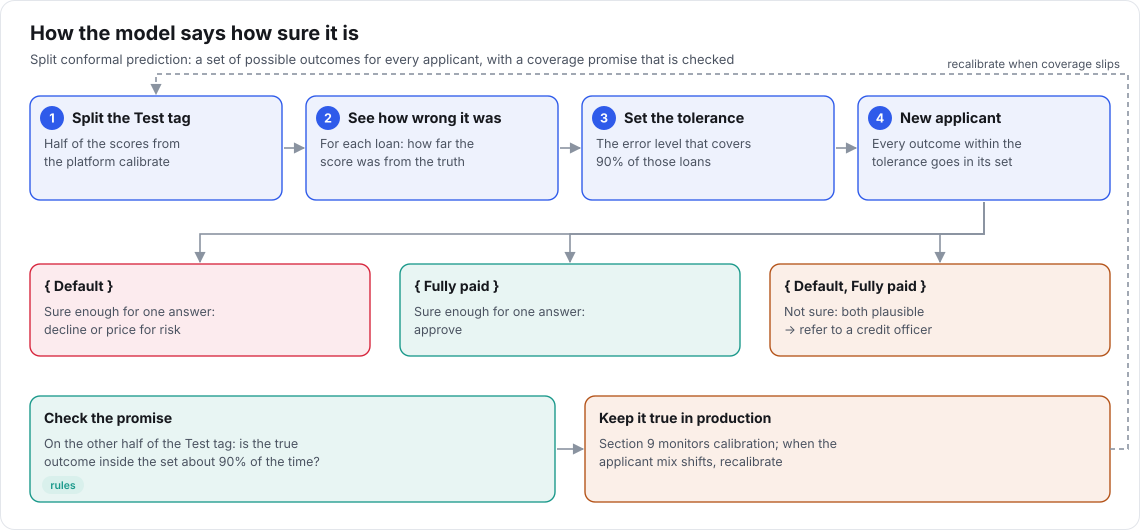

In [ ]:
# @title Diagram: how uncertainty is measured { display-mode: "form" }
from IPython.display import SVG, display
display(SVG(data='<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 1140 530" width="1140" height="530" font-family="Inter, \'Helvetica Neue\', Helvetica, Arial, sans-serif" role="img" aria-label="How the model says how sure it is"><defs><marker id="arr" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 z" fill="#8A93A0"/></marker></defs><rect x="0.5" y="0.5" width="1139" height="529" rx="14" fill="#FFFFFF" stroke="#E3E6EB"/><text x="30" y="40" font-size="20" fill="#16181D" font-weight="700" text-anchor="start">How the model says how sure it is</text><text x="30" y="64" font-size="13" fill="#4A5260" font-weight="400" text-anchor="start">Split conformal prediction: a set of possible outcomes for every applicant, with a coverage promise that is checked</text><rect x="30" y="96" width="252" height="104" rx="10" fill="#EEF2FD" stroke="#2F5BEA" stroke-width="1.4"/><circle cx="52" cy="118" r="12" fill="#2F5BEA"/><text x="52" y="122.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">1</text><text x="72" y="123" font-size="14.5" fill="#16181D" font-weight="700" text-anchor="start">Split the Test tag</text><text x="44" y="148" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Half of the scores from</text><text x="44" y="166" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">the platform calibrate</text><path d="M284,148.0 L304,148.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="306" y="96" width="252" height="104" rx="10" fill="#EEF2FD" stroke="#2F5BEA" stroke-width="1.4"/><circle cx="328" cy="118" r="12" fill="#2F5BEA"/><text x="328" y="122.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">2</text><text x="348" y="123" font-size="14.5" fill="#16181D" font-weight="700" text-anchor="start">See how wrong it was</text><text x="320" y="148" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">For each loan: how far the</text><text x="320" y="166" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">score was from the truth</text><path d="M560,148.0 L580,148.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="582" y="96" width="252" height="104" rx="10" fill="#EEF2FD" stroke="#2F5BEA" stroke-width="1.4"/><circle cx="604" cy="118" r="12" fill="#2F5BEA"/><text x="604" y="122.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">3</text><text x="624" y="123" font-size="14.5" fill="#16181D" font-weight="700" text-anchor="start">Set the tolerance</text><text x="596" y="148" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">The error level that covers</text><text x="596" y="166" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">90% of those loans</text><path d="M836,148.0 L856,148.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="858" y="96" width="252" height="104" rx="10" fill="#EEF2FD" stroke="#2F5BEA" stroke-width="1.4"/><circle cx="880" cy="118" r="12" fill="#2F5BEA"/><text x="880" y="122.5" font-size="12.5" fill="#FFFFFF" font-weight="700" text-anchor="middle">4</text><text x="900" y="123" font-size="14.5" fill="#16181D" font-weight="700" text-anchor="start">New applicant</text><text x="872" y="148" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Every outcome within the</text><text x="872" y="166" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">tolerance goes in its set</text><rect x="30" y="264" width="340" height="92" rx="10" fill="#FCEBEE" stroke="#D7263D" stroke-width="1.4"/><text x="44" y="291" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">{ Default }</text><text x="44" y="316" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Sure enough for one answer:</text><text x="44" y="334" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">decline or price for risk</text><path d="M984.0,202 L984.0,234 L200.0,234 L200.0,262" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="400" y="264" width="340" height="92" rx="10" fill="#E8F5F3" stroke="#1B998B" stroke-width="1.4"/><text x="414" y="291" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">{ Fully paid }</text><text x="414" y="316" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Sure enough for one answer:</text><text x="414" y="334" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">approve</text><path d="M984.0,202 L984.0,234 L570.0,234 L570.0,262" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="770" y="264" width="340" height="92" rx="10" fill="#FBEFE8" stroke="#B4541A" stroke-width="1.4"/><text x="784" y="291" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">{ Default, Fully paid }</text><text x="784" y="316" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Not sure: both plausible</text><text x="784" y="334" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">→ refer to a credit officer</text><path d="M984.0,202 L984.0,234 L940.0,234 L940.0,262" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><rect x="30" y="396" width="525" height="106" rx="10" fill="#E8F5F3" stroke="#1B998B" stroke-width="1.4"/><text x="44" y="423" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Check the promise</text><text x="44" y="448" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">On the other half of the Test tag: is the true</text><text x="44" y="466" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">outcome inside the set about 90% of the time?</text><rect x="42" y="476" width="42" height="18" rx="9" fill="#D9F0EC"/><text x="63.0" y="489" font-size="10.5" fill="#1B998B" font-weight="600" text-anchor="middle">rules</text><rect x="585" y="396" width="525" height="106" rx="10" fill="#FBEFE8" stroke="#B4541A" stroke-width="1.4"/><text x="599" y="423" font-size="14" fill="#16181D" font-weight="700" text-anchor="start">Keep it true in production</text><text x="599" y="448" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">Section 9 monitors calibration; when the</text><text x="599" y="466" font-size="12.5" fill="#4A5260" font-weight="400" text-anchor="start">applicant mix shifts, recalibrate</text><path d="M557,449.0 L583,449.0" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)"/><path d="M1110,449.0 L1128,449.0 L1128,74 L156.0,74 L156.0,94" stroke="#8A93A0" stroke-width="1.6" fill="none" marker-end="url(#arr)" stroke-dasharray="5 4"/><text x="1120" y="68" font-size="11.5" fill="#4A5260" font-weight="400" text-anchor="end">recalibrate when coverage slips</text></svg>'))

In [ ]:
# @title Uncertainty with measured coverage, and fairness by group { display-mode: "form" }
# Split conformal on the platform's own scores: half of the Test tag calibrates, the other half checks the promise
ALPHA = 0.10
rng_ = np.random.default_rng(0); idx = rng_.permutation(len(y)); cal, ev = idx[: len(y) // 2], idx[len(y) // 2:]
if TASK == "classification":
    score_true = np.where(y[cal] == 1, 1 - p_te[cal], p_te[cal])                 # how wrong the model was about the true class
    q = float(np.quantile(score_true, min(1.0, np.ceil((len(cal) + 1) * (1 - ALPHA)) / len(cal))))
    in0, in1 = (p_te[ev] <= q), ((1 - p_te[ev]) <= q)                            # is class 0 / class 1 inside the set?
    sizes_ = in0.astype(int) + in1.astype(int)
    covered = np.where(y[ev] == 1, in1, in0)
    unc = {"target_coverage": 1 - ALPHA, "measured_coverage": float(covered.mean()), "share_single_answer": float((sizes_ == 1).mean()),
           "share_needs_review": float((sizes_ != 1).mean())}
    fig = make_subplots(rows=1, cols=2, subplot_titles=("Coverage: promised vs measured", "Prediction-set size"))
    vc = pd.Series(sizes_).value_counts().sort_index()
    fig.add_trace(go.Bar(x=[{0: "abstain", 1: "one answer", 2: "both possible"}[int(k)] for k in vc.index], y=vc.values, marker_color=BLUE, showlegend=False), 1, 2)
else:
    q = float(np.quantile(np.abs(y[cal] - p_te[cal]), min(1.0, np.ceil((len(cal) + 1) * (1 - ALPHA)) / len(cal))))
    covered = np.abs(y[ev] - p_te[ev]) <= q
    unc = {"target_coverage": 1 - ALPHA, "measured_coverage": float(covered.mean()), "interval_half_width": q,
           "interval_width_vs_median_target_pct": float(2 * q / np.median(y) * 100)}
    o = np.argsort(p_te[ev])[:: max(1, len(ev) // 120)]
    fig = make_subplots(rows=1, cols=2, column_widths=[0.3, 0.7], subplot_titles=("Coverage: promised vs measured", "90% intervals for a sample (sorted by prediction)"))
    xs = np.arange(len(o))
    fig.add_trace(go.Scatter(x=np.r_[xs, xs[::-1]], y=np.r_[p_te[ev][o] + q, (p_te[ev][o] - q)[::-1]], fill="toself", fillcolor="rgba(47,91,234,0.18)", line=dict(width=0), name="90% interval"), 1, 2)
    fig.add_trace(go.Scatter(x=xs, y=y[ev][o], mode="markers", marker=dict(color=ORANGE, size=5), name="actual"), 1, 2)
fig.add_trace(go.Bar(x=["promised", "measured"], y=[1 - ALPHA, unc["measured_coverage"]], marker_color=[GREY, TEAL], showlegend=False,
                     text=[f"{1 - ALPHA:.0%}", f"{unc['measured_coverage']:.1%}"], textposition="outside"), 1, 1)
fig.update_layout(template="plotly_white", height=400, title="Uncertainty: split conformal prediction on the platform's scores")
fig.show()
record("uncertainty", method="split conformal prediction on platform scores; half of the Test tag calibrates, half verifies", **unc)

# Fairness by group, from the platform's scores
gcols = [c for c in test.columns if c.startswith(GROUP_PREFIX)]
gser = (test[gcols].idxmax(axis=1).str.replace(GROUP_PREFIX, "") if len(gcols) > 1 else test[gcols[0]].astype(str)) if gcols else pd.Series("all", index=test.index)
group = scored[UID].astype(str).map(dict(zip(test[UID].astype(str), gser))).fillna("other").to_numpy()
if TASK == "classification":
    flag = (p_te >= THRESHOLD).astype(int)
    tab = pd.DataFrame({"g": group, "y": y, "flag": flag}).groupby("g").apply(lambda d: pd.Series({
        "rows": len(d), "base_rate": d.y.mean(), "selection_rate": d.flag.mean(), "true_positive_rate": d.flag[d.y == 1].mean(), "false_positive_rate": d.flag[d.y == 0].mean()}))
    fair = {"demographic_parity_difference": float(tab.selection_rate.max() - tab.selection_rate.min()),
            "disparate_impact_ratio": float(tab.selection_rate.min() / max(tab.selection_rate.max(), 1e-9)),
            "equal_opportunity_difference": float(tab.true_positive_rate.max() - tab.true_positive_rate.min())}
else:
    tab = pd.DataFrame({"g": group, "y": y, "p": p_te}).groupby("g").apply(lambda d: pd.Series({
        "rows": len(d), "mean_actual": d.y.mean(), "mean_prediction": d.p.mean(), "mae": (d.y - d.p).abs().mean()}))
    fair = {"mean_prediction_ratio": float(tab.mean_prediction.min() / tab.mean_prediction.max()), "mae_ratio": float(tab.mae.min() / tab.mae.max())}
tab = tab[tab.rows >= 30] if (tab.rows >= 30).sum() >= 2 else tab
display(tab.style.format(precision=3).set_caption(f"Fairness by {GROUP_LABEL}, computed from the platform's scores"))
record("fairness", attribute=GROUP_LABEL, groups=len(tab), **fair)
record("limitations", note_1="fairness is measured on one attribute available in the data; other protected attributes were not available",
       note_2="zero-shot foundation models depend on the uploaded context rows; refresh the Training tag when the population shifts",
       note_3="results come from a sample of the source data, not the full portfolio")

In [ ]:
# @title In this run, in plain English { display-mode: "form" }
def _verdict(promised, measured, noun="sets"):
    gap = measured - promised
    if abs(gap) <= 2:
        return "close to the promise"
    return (f"above the promise (the {noun} are a little cautious, which is the safe side)" if gap > 0
            else f"below the promise: treat the {noun} with care and recalibrate before relying on them")

U = FACTS["uncertainty"]
pr, ms = U["target_coverage"] * 100, U["measured_coverage"] * 100
display(Markdown(f"""**In this run, in plain English**
- We promised that the true outcome would be inside the prediction set for **{pr:.0f}%** of applicants. On the half of the Test tag kept for checking it was inside for **{ms:.1f}%**, {_verdict(pr, ms)}.
- **{U['share_single_answer']:.0%}** of applicants got one confident answer; **{U['share_needs_review']:.0%}** would go to a credit officer."""))

## 7.3 Observations and policies
Two platform guardrails sit next to the model and travel with every case:

- **Observations** are named facts about a case: an expression over its features plus a plain-English statement. They explain *why a case deserves attention* without changing the decision.
- **Policies** are rules that **override** the model's output with a decision when their expression is true (for example, always refer a case to manual review), in priority order, optionally for chosen models only.

Expressions use feature names, the operators `==`, `!==`, `>`, `<`, `in`, `notin`, `contains`, `notcontains`, the connectors `and` / `or`, and parentheses. Comparison values are whole words or whole numbers (the SDK's parser reads `\w+`, so no decimals or minus signs). Statements can quote a feature value with `{feature}`.

The cell below proposes observations and policies from the selected model's strongest features; each is created through the SDK after a human gate and then appears on every case scored with `risk_policies=True` (section 8.2).

In [ ]:
# @title Propose observations and policies from the strongest features { display-mode: "form" }
_OPS = ("in", "notin", "contains", "notcontains")
num_ = scored.select_dtypes("number")


def _threshold(feature, q):
    """A whole-number threshold the expression parser accepts: no decimals, no minus sign, digits not inside the feature name."""
    v = int(np.floor(float(num_[feature].quantile(q))))
    return v if v >= 0 and str(v) not in feature else None


cands = [c for c in drivers if c in num_ and num_[c].nunique() > 20 and c not in (UID, TARGET_COL)] + \
        [c for c in num_.columns if c not in drivers and num_[c].nunique() > 20 and c not in (UID, TARGET_COL, PRED, "Predicted_value_AutoML", "pred_proba_AutoML")]
OBS_SPECS = []
for f in cands:
    hi = _threshold(f, 0.90)
    share = float((num_[f] > hi).mean()) if hi is not None else 0.0
    if hi is None or not 0.02 <= share <= 0.40:
        continue
    OBS_SPECS.append({"observation_name": f"High {f}"[:40], "expression": f"{f} > {hi}",
                      "statement": f"{f} is in the top {share:.0%} of the portfolio: {{{f}}}", "linked_features": [f]})
    if len(OBS_SPECS) == 3:
        break
POLICY_SPECS = []
pair = next(((a, b) for a in OBS_SPECS for b in OBS_SPECS if a is not b and not b["linked_features"][0].startswith(_OPS)), None)
if pair:
    a, b = pair; fa, fb = a["linked_features"][0], b["linked_features"][0]
    POLICY_SPECS.append({"policy_name": "Two risk flags together", "expression": f"{a['expression']} and {b['expression']}",
                         "statement": f"{fa} and {fb} are both unusually high: {{{fa}}}, {{{fb}}}", **POLICY_DECISION, "priority": 1})
if OBS_SPECS:
    f = OBS_SPECS[0]["linked_features"][0]; vh = _threshold(f, 0.98)
    if vh is not None and vh > int(OBS_SPECS[0]["expression"].split(">")[1]):
        POLICY_SPECS.append({"policy_name": f"Extreme {f}"[:40], "expression": f"{f} > {vh}", "statement": f"{f} is extreme: {{{f}}}", **POLICY_DECISION, "priority": 2})
show_ = lambda specs, cols, cap: display(pd.DataFrame(specs)[cols].style.hide(axis="index").set_caption(cap)) if specs else print(f"{cap}: none proposed")
show_(OBS_SPECS, ["observation_name", "expression", "statement"], "Observations proposed (thresholds from the scored data)")
show_([{**p, "decision": p.get("input") or p["decision"]} for p in POLICY_SPECS], ["policy_name", "expression", "decision", "priority"], "Policies proposed")

In [ ]:
params = attempt("expression parameters (features, operators, decisions)", lambda: project.get_observation_params(), default={})
have = set(as_frame(attempt("observations", lambda: project.observations(), show=False)).get("observation_name", []))
for spec in OBS_SPECS:
    if spec["observation_name"] not in have and human_gate(f"Create observation '{spec['observation_name']}' ({spec['expression']})?", True):
        attempt(f"create_observation · {spec['observation_name']}", lambda s=spec: project.create_observation(**s))
as_frame(attempt("observations", lambda: project.observations(), show=False))

In [ ]:
have = set(as_frame(attempt("policies", lambda: project.policies(), show=False)).get("policy_name", []))
for spec in POLICY_SPECS:
    if spec["policy_name"] not in have and human_gate(f"Create policy '{spec['policy_name']}' ({spec['expression']})?", True):
        attempt(f"create_policy · {spec['policy_name']}", lambda s=spec: project.create_policy(models=[CHAMPION_BUILD], **s))
as_frame(attempt("policies", lambda: project.policies(), show=False))

## 7.4 Regulatory evidence map

In [ ]:
# @title Which evidence supports which expectation { display-mode: "form" }
REG_MAP = pd.DataFrame([
    ("Conceptual soundness", "Problem statement, data preparation log, feature rationale, model selection rule", "SR 11-7 · SAMA model risk expectations"),
    ("Data quality and lineage", "Data profile, agent action log with human approvals, leakage checks", "SAMA Data Management · NDMO standards · PDPL"),
    ("Outcomes analysis", "Hold-out metrics, evaluation dashboards, segment performance", "SR 11-7 · Basel sound-practice principles"),
    ("Uncertainty", "Conformal prediction with measured coverage, calibration", "SR 11-7 (model limitations) · CBB AI policy"),
    ("Fairness", "Group metrics on protected or proxy attributes", "SDAIA AI Ethics Principles · CBB AI policy · EU AI Act"),
    ("Explainability", "Global drivers and per-decision explanations", "SDAIA AI Ethics Principles · EU AI Act"),
    ("Ongoing monitoring", "Drift monitoring, performance tracking, retraining with approval gate", "SR 11-7 · SAMA model risk expectations"),
    ("Documentation", "Generated model card with grounding check, audit trail", "SR 11-7 · ISO/IEC 42001"),
], columns=["Expectation", "Evidence produced in this notebook", "Frameworks it speaks to"])
display(REG_MAP.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"})
        .set_caption("Frameworks are named for orientation only. The bank's Compliance and Risk functions own the control mapping; "
                     "no clause-level compliance is claimed here."))
n_obs = len(as_frame(attempt("observations", lambda: project.observations(), show=False)))
n_pol = len(as_frame(attempt("policies", lambda: project.policies(), show=False)))
record("governance", frameworks_referenced="SR 11-7; SAMA model risk expectations; SAMA and NDMO data standards; PDPL; CBB AI policy; SDAIA AI Ethics Principles; EU AI Act; ISO/IEC 42001",
       platform_observations=n_obs, platform_policies=n_pol, human_approval_gates=sum(1 for a in AUDIT if a["actor"] == "human"),
       llm_reviewed_agent_steps=sum(1 for t in AGENT_TRACE if t["decision"] in ("approve", "reject")))

# 8 · Artefacts before production

## 8.1 Model card through the gateway
Written by the `card_writer` model **only from the facts this notebook recorded** (from the platform), against a documentation standard for a model-risk committee, then checked automatically and revised once. Only the aggregate fact sheet is sent.

In [ ]:
# @title The documentation standard: system prompt, 14-section template, metric notes { display-mode: "form" }
import html as _html, textwrap
REVISION_PASS = True

CARD_SECTIONS = [
    "0. Document control", "1. Executive summary", "2. Intended use and scope", "3. Data", "4. Methodology and model selection",
    "5. Performance on held-out data", "6. Explainability", "7. Uncertainty and calibration", "8. Fairness",
    "9. Limitations and known risks", "10. Monitoring, alerting and retraining", "11. Regulatory alignment",
    "12. Approvals and sign-off", "13. Change log",
]

SYSTEM_PROMPT = textwrap.dedent("""
# ROLE
You are a senior model-risk documentation specialist at a Gulf bank supervised by SAMA (Saudi Central Bank) and the
Central Bank of Bahrain. You write the model card that goes to three readers:
- the model-risk committee, who decide whether the model may be used and read sections 0, 1, 9 and 12 first;
- the independent validator, who checks every number against the evidence;
- the supervisor's examiner, who looks for honest limitations and working controls.
A card that overstates, invents or cannot be traced is worse than no card. Precision and traceability come before style.

# SOURCE OF TRUTH
The user message contains a FACT SHEET. It is the only source you may use. Each fact has a key, for example
`performance.roc_auc = 0.7277`. The part before the dot is the fact group (data, preparation, selection, performance ...).

# CITATION RULES
1. Every number you write is followed immediately by the key it came from, in square brackets.
   Right:  The model reaches a ROC AUC of 0.728 [performance.roc_auc] on 3,000 unseen loans [performance.test_rows].
   Wrong:  The model reaches a ROC AUC of about 0.73 on the test set.            (no key; "about")
   Wrong:  ROC AUC improved by 0.015 over the baseline.                           (a number you computed)
2. Inside a table, put the key in the "Source" column of the same row instead of in brackets.
3. Use a key only for the fact it names. Never attach a key to a different number.
4. Text facts (model names, feature names, methods, rules) are quoted as written and also carry their key.

# NUMBER RULES
5. Round, never change: scores to 3 decimals, counts to whole numbers with thousands separators, percentages to 1 decimal.
6. A fact stored as a share (0.9017) may be written as a percentage (90.2%) with the same key. Say which it is.
7. Do NO arithmetic. Do not write differences, ratios, sums, averages or percentage changes that are not themselves facts.
   To compare two facts, state both with their keys and say which is higher, lower or about equal.
8. If something the template asks for is not in the fact sheet, write exactly "Not recorded". Never estimate or infer it.

# NEVER WRITE
9. Dates, people's names, team names, committee names, ticket numbers or version numbers that are not in the fact sheet.
10. Approvals, validation outcomes or sign-offs. Every approval is "Pending". The risk tier is "To be assigned by Model Risk Management".
11. Regulation article, clause or circular numbers, and any statement that the model "complies", "is compliant" or "meets"
    a regulation. Name a framework only if it appears in the fact sheet, and describe the evidence, not compliance.
12. Marketing language: "state-of-the-art", "robust", "best-in-class", "ensures", "guarantees", "cutting-edge".
13. Advice the facts do not support (for example recommending a threshold or a new feature).

# WHAT EACH SECTION MUST CONTAIN
0 Document control: the table, filled from use_case.* and the values marked "given".
1 Executive summary: exactly five bullets, in this order: what the model decides and for whom; which model was selected and
  how (selection.*); the headline held-out result with its metric explained in a few words (performance.*); how uncertainty
  is handled (uncertainty.*); the single most important risk to watch (limitations.* or monitoring.*). No bullet over 35 words.
2 Intended use and scope: the decision supported, intended users (only if recorded), the population the data covers, and an
  "Out of scope" list of at least three uses the facts do not support (other products, other populations, automated decisions
  without the recorded human review, and so on, phrased as limits of the evidence).
3 Data: source and size; a table of the data sets with rows and purpose; candidate features and what remained after
  preparation; what the data-preparation agent removed and why, including leakage controls (preparation.*); data-quality
  findings (missing values, skew); engineered features (features.*).
4 Methodology and model selection: how many candidates were raced and how many succeeded; the selection rule in plain words;
  the selected model and whether it is zero-shot, fine-tuned or trained; the hyperparameter search; why it won
  (selection.selection_reason if recorded); the hardware (training.*).
5 Performance on held-out data: the table with one row per performance.* fact and a plain-English "What it means" taken from
  the METRIC NOTES; then two or three sentences comparing the selected model with the best classic baseline (state both
  numbers, no arithmetic) and saying what the result means for the decision.
6 Explainability: the global method and the top drivers named in plain words; how single decisions are explained; a caution
  that importance shows association with the prediction, not cause.
7 Uncertainty and calibration: the method; promised versus measured coverage; what happens to uncertain cases; calibration
  figures if recorded.
8 Fairness: the table with one row per fairness.* fact; the attribute used and the number of groups; a neutral reading of the
  largest gap; a statement that other protected attributes were not assessed if the facts say so. No legal conclusions.
  For forecasting models write that fairness metrics do not apply and report consistency across segments instead.
9 Limitations and known risks: a numbered list of at least four items. Each item has three parts: the limitation, why it
  matters for the decision, and the control or monitor that addresses it (from monitoring.*, uncertainty.* or governance.*),
  or "No control recorded".
10 Monitoring, alerting and retraining: the monitors; the alert thresholds if recorded; how alerts reach the retraining
  agent; the champion-challenger rule and promotion margin; every human approval gate; then what monitoring has observed so
  far and every retraining event (retraining.*). If there are no observations yet, say "No production observations yet".
11 Regulatory alignment: the table. For each expectation list the card sections that hold the evidence, write the status as
  "Evidence provided" or "Not recorded", and cite one fact key. Close with one sentence naming the frameworks in
  governance.frameworks_referenced and stating that control mapping is owned by the bank's Compliance function.
12 Approvals and sign-off: the table with every cell "Pending", followed by "Open items for the validator": a bullet for
  every "Not recorded" you wrote in the card, or "None" if there were none.
13 Change log: every change supplied by the user, as bullets in the order given, or "Initial version".

# STYLE
- Plain English, short sentences, active voice. Explain each metric in a few words the first time it appears.
- Prefer tables for numbers and bullets for lists. No paragraph longer than four sentences.
- Feature names are written as recorded, in backticks.
- Target length: 900 to 1,500 words excluding tables.

# BEFORE YOU ANSWER, CHECK
- Every number has a key next to it or in its row, and the key exists in the fact sheet.
- No number was computed by you. No date, name, approval or clause number was invented.
- All 14 headings are present, numbered 0 to 13, in order, exactly as in the template.
- Every "Not recorded" in the card is listed under section 12.

# EXTRA RULES
- Square brackets contain ONLY a fact key, nothing else. Never write notes, reasoning or "not recorded" inside brackets.
  If the exact fact is missing, use the closest fact that is recorded with its own key, or write "Not recorded" in plain text.
- In section 11 the status may be "Evidence provided", "Partly provided: <which part>", "Not applicable: <why>" or "Not recorded".
  Use "Not recorded" only when no section of the card holds any evidence for that expectation.

# OUTPUT
Markdown only. Start with the line "# Model card · <use-case name>" and end with the last line of section 13.
No preamble, no closing remarks, no code fence around the card.
""").strip()

CARD_TEMPLATE = textwrap.dedent("""
# Model card · <use-case name>

## 0. Document control
| Field | Value | Source |
|---|---|---|
| Model name | <use-case name> | use_case.name |
| Model version | <version> | use_case.version |
| Card version | <card version given by the user> | given |
| Status | Draft, pending independent validation | given |
| Model owner | <owner> | use_case.owner |
| Risk tier | To be assigned by Model Risk Management | given |
| Written by | <writer given by the user> | given |

## 1. Executive summary
<five bullets as specified>

## 2. Intended use and scope
<decision supported, intended users, population in scope>

**Out of scope**
<at least three bullets>

## 3. Data
<source and size in one or two sentences>

| Data set | Rows | Used for | Source |
|---|---|---|---|
<one row per recorded data set>

<features before and after preparation; what the agent removed and why; leakage controls; data-quality findings; engineered features>

## 4. Methodology and model selection
<candidates, selection rule, selected model, adaptation, hyperparameter search, why it won, hardware>

## 5. Performance on held-out data
| Metric | Value | What it means | Source |
|---|---|---|---|
<one row per recorded performance fact>

<comparison with the best classic baseline, and what the result means for the decision>

## 6. Explainability
<global method and top drivers; single-decision explanations; the association-not-cause caution>

## 7. Uncertainty and calibration
<method, promised vs measured coverage, treatment of uncertain cases, calibration>

## 8. Fairness
| Metric | Value | Source |
|---|---|---|
<one row per recorded fairness fact, or a single row "Not recorded">

<neutral interpretation and limits>

## 9. Limitations and known risks
<numbered list; each item: limitation · why it matters · control or monitor>

## 10. Monitoring, alerting and retraining
<monitors, thresholds, alert routing, champion-challenger rule, approval gates>

**Observed so far**
<observations and retraining events, or "No production observations yet">

## 11. Regulatory alignment
| Expectation | Evidence in this card | Status | Source |
|---|---|---|---|
| Conceptual soundness | <sections> | <status> | <key> |
| Data quality and lineage | <sections> | <status> | <key> |
| Outcomes analysis | <sections> | <status> | <key> |
| Ongoing monitoring | <sections> | <status> | <key> |
| Explainability and fairness | <sections> | <status> | <key> |
| Documentation and change control | <sections> | <status> | <key> |

<one sentence naming the frameworks in the fact sheet; control mapping is owned by the bank's Compliance function>

## 12. Approvals and sign-off
| Role | Name | Decision | Date |
|---|---|---|---|
| Model owner | Pending | Pending | Pending |
| Independent model validation | Pending | Pending | Pending |
| Model risk committee | Pending | Pending | Pending |

**Open items for the validator**
<one bullet per "Not recorded" in this card, or "None">

## 13. Change log
<bullets>
""").strip()

# Plain-English meanings the writer may use in the "What it means" column (deliberately free of numbers)
METRIC_NOTES = {
    "roc_auc": "how well the model ranks risky cases above safe ones; higher is better",
    "average_precision": "how concentrated the true positives are among the highest scores; higher is better",
    "f1": "balance of precision and recall at the chosen threshold; higher is better",
    "precision": "of the cases the model flags, the share that are truly positive",
    "recall": "of the truly positive cases, the share the model flags",
    "accuracy": "share of all cases classified correctly at the chosen threshold",
    "balanced_accuracy": "accuracy averaged over the two classes, so the rarer class counts equally",
    "mcc": "single summary of the confusion matrix that stays fair when classes are unbalanced; higher is better",
    "brier": "average squared gap between predicted probability and outcome; lower is better",
    "log_loss": "penalty for confident wrong probabilities; lower is better",
    "ks": "largest separation between the score distributions of the two classes; higher is better",
    "gini": "a rescaling of ROC AUC used in credit scoring; higher is better",
    "threshold": "the score above which a case is flagged; chosen on validation data",
    "r2": "share of the variation in the target that the model explains; higher is better",
    "rmse": "typical size of the error, with large errors weighted more; in the target's units; lower is better",
    "mae": "average size of the error in the target's units; lower is better",
    "median_abs_error": "the error size that half of the predictions stay within; lower is better",
    "mape_pct": "average error as a percentage of the actual value; lower is better",
    "explained_variance": "share of the target's variation captured by the predictions; higher is better",
    "max_error": "the single largest error on the test set",
    "within_20pct_share": "percentage of predictions that land within one fifth of the actual value",
    "mase": "forecast error relative to a seasonal-naive forecast; below one beats it; lower is better",
    "wql": "error of the whole predicted range, not just the middle; lower is better",
    "smape": "symmetric percentage error of the median forecast; lower is better",
    "wape_pct": "total absolute error as a percentage of total actual flow; lower is better",
    "inside_90_band_pct": "percentage of actual outcomes that fell inside the ninety-percent band",
    "inside_80_band_pct": "percentage of actual outcomes that fell inside the eighty-percent band",
    "batch_rows_per_second": "scoring throughput in batch mode",
    "measured_coverage": "share of test cases whose true outcome fell inside the prediction set or interval",
    "disparate_impact_ratio": "lowest group selection rate divided by the highest; closer to one means more equal",
    "demographic_parity_difference": "gap between the highest and lowest group selection rates; closer to zero is more equal",
    "equal_opportunity_difference": "gap between groups in the share of true positives that are flagged",
    "equalized_odds_difference": "the larger of the gaps in true-positive and false-positive rates between groups",
    "predictive_parity_difference": "gap between groups in the precision of the flag",
    "max_feature_psi": "largest population stability index of any monitored feature; higher means more drift",
}

SECTION_GUIDE = {"use_case": "0, 1, 2", "data": "3", "preparation": "3", "features": "3", "selection": "4", "training": "4",
                 "performance": "1, 5", "explainability": "6", "uncertainty": "7", "fairness": "8", "limitations": "9",
                 "monitoring": "10", "retraining": "10, 13", "governance": "11"}


def flatten_facts(facts):
    flat = {}
    for sec, vals in facts.items():
        for k, v in vals.items():
            if isinstance(v, (np.floating, np.integer)):
                v = float(v)
            if isinstance(v, float) and not np.isfinite(v):
                continue
            flat[f"{sec}.{k}"] = v
    return flat


def build_messages(facts, changes, version_label, writer_label):
    flat = flatten_facts(facts)
    groups = {}
    for k, v in flat.items():
        groups.setdefault(k.split(".", 1)[0], []).append(f"- {k} = {v}")
    fact_block = "\n\n".join(f"[{g}]  (mainly for section {SECTION_GUIDE.get(g, 'as relevant')})\n" + "\n".join(lines) for g, lines in groups.items())
    notes = "\n".join(f"- {k}: {METRIC_NOTES[k.split('.', 1)[1]]}" for k in flat if k.split(".", 1)[1] in METRIC_NOTES)
    change_lines = "\n".join(f"- {c}" for c in changes) if changes else "- Initial version"
    user = (f"Write the model card, card version {version_label}. It is being written by: {writer_label}.\n\n"
            f"=== TEMPLATE (reproduce the headings and tables exactly; replace each <instruction>) ===\n\n{CARD_TEMPLATE}\n\n"
            f"=== FACT SHEET ({len(flat)} facts; the only source you may use; cite the key after every number) ===\n\n{fact_block}\n\n"
            f"=== METRIC NOTES (plain-English meanings for the 'What it means' column) ===\n{notes or '- none'}\n\n"
            f"=== CHANGES SINCE THE PREVIOUS VERSION (for section 13) ===\n{change_lines}\n")
    return SYSTEM_PROMPT, user


def writer_label():
    return f"{LEXSI_PROVIDER} · {LEXSI_MODEL} through the Lexsi LLM gateway" if WRITER == "lexsi" else (
        "open-weights model on the notebook GPU" if WRITER not in ("template",) else "template writer (no LLM)")


def show_prompt(version_label="v1", changes=None):
    system, user = build_messages(FACTS, changes, version_label, writer_label())
    display(Markdown(f"**Prompt sent to the writer:** system prompt {len(system):,} characters · user message {len(user):,} characters "
                     f"(about {(len(system) + len(user)) // 4:,} tokens) · {len(flatten_facts(FACTS))} facts · no customer-level data."))
    for title, body in (("System prompt: role, citation rules, section requirements, self-check", system),
                        ("User message: template, fact sheet, metric notes, changes", user)):
        display(HTML(f"<details><summary><b>{title}</b> · click to expand</summary>"
                     f"<pre style='white-space:pre-wrap;font-size:12px'>{_html.escape(body)}</pre></details>"))

In [ ]:
# @title Writer through the gateway, template fallback and the automatic checks { display-mode: "form" }
# The model card is written through the same gateway, by the model assigned to the "card_writer" role
LEXSI_PROVIDER, LEXSI_MODEL = GATEWAY_MODELS["card_writer"]
LEXSI_PROJECT = LLM_PROJECT_ID
WRITER = "lexsi" if gateway_ready() else "template"


def write_lexsi(system, messages):
    max_tokens = CARD_MAX_TOKENS
    for attempt_ in range(2):
        res = llm_call("card_writer", [{"role": "system", "content": system}, *messages], max_tokens=max_tokens, agent="model-card writer",
                       step="revision" if len(messages) > 1 else "draft")
        if res["finish_reason"] in ("length", "max_tokens") and attempt_ == 0:
            print(f"answer cut off at {max_tokens:,} tokens → asking again with {max_tokens * 2:,}")
            max_tokens *= 2
            continue
        break
    text = res["text"]
    if "# Model card" in text:
        text = text[text.index("# Model card"):]
    text = re.sub(r"^```(?:markdown)?\s*|\s*```$", "", text.strip())
    AGENT_TRACE[-1].update(decision="card written", rationale=f"{len(text):,} characters")
    return text, res["reasoning"], {"writer": f"{res['provider']} · {res['model']} (Lexsi gateway, via {res['via']})", "max_tokens_used": max_tokens,
                                    "input_tokens": res["input_tokens"], "output_tokens": res["output_tokens"], "finish_reason": res["finish_reason"],
                                    "lexsi_project": LLM_PROJECT_ID, "gateway_seconds": res["seconds"]}

print("model-card writer:", f"{LEXSI_PROVIDER} · {LEXSI_MODEL} through the Lexsi gateway" if WRITER == "lexsi" else "template (no gateway configured)")
write_local = None


def write_template(facts, changes, version_label):
    """Deterministic writer: fills the same template from the facts, with a citation after every number."""
    flat = flatten_facts(facts)
    def cite(key, label=None):
        v = flat.get(key)
        if v is None:
            return "Not recorded"
        if isinstance(v, float):
            v = f"{v:,.4g}" if abs(v) < 1000 else f"{v:,.0f}"
        return f"{v} [{key}]"
    rows = lambda sec: [(k.split(".", 1)[1], k) for k in flat if k.startswith(sec + ".")]
    table = lambda sec: "\n".join(f"| {name.replace('_', ' ')} | {cite(k)} | {k} |" for name, k in rows(sec)) or "| Not recorded | Not recorded | — |"
    uc = lambda k: flat.get(f"use_case.{k}", "Not recorded")
    L = [f"# Model card · {uc('name')}", "", "## 0. Document control", "| Field | Value | Source |", "|---|---|---|",
         f"| Model name | {uc('name')} | use_case.name |", f"| Model version | {uc('version')} | use_case.version |",
         f"| Card version | {version_label} | given |", "| Status | Draft, pending independent validation | given |",
         f"| Model owner | {uc('owner')} | use_case.owner |", "| Risk tier | To be assigned by Model Risk Management | given |",
         "| Written by | template writer (no LLM) | given |", "",
         "## 1. Executive summary", f"- Decision supported: {uc('decision_supported')}.",
         f"- Selected model: {cite('selection.selected_model')}.", f"- Selection metric: {cite('selection.selection_metric')}.",
         "- Held-out performance: see section 5.", "- Main risk to watch: drift in the population; see sections 9 and 10.", "",
         "## 2. Intended use and scope", f"- Task: {uc('task')}.", f"- Decision supported: {uc('decision_supported')}.",
         "- Out of scope: any use not described in the facts.", "",
         "## 3. Data", "| Item | Value | Source |", "|---|---|---|", table("data"), table("preparation"), table("features"), "",
         "## 4. Methodology and model selection", "| Item | Value | Source |", "|---|---|---|", table("selection"), table("training"), "",
         "## 5. Performance on held-out data", "| Metric | Value | What it means | Source |", "|---|---|---|---|",
         "\n".join(f"| {n.replace('_', ' ')} | {cite(k)} | — | {k} |" for n, k in rows("performance")) or "| Not recorded | — | — | — |", "",
         "## 6. Explainability", "| Item | Value | Source |", "|---|---|---|", table("explainability"), "",
         "## 7. Uncertainty and calibration", "| Item | Value | Source |", "|---|---|---|", table("uncertainty"), "",
         "## 8. Fairness", "| Metric | Value | Source |", "|---|---|---|", table("fairness"), "",
         "## 9. Limitations and known risks", *[f"{i}. {flat[k]}" for i, k in enumerate([k for k in flat if k.startswith("limitations.")], 1)], "",
         "## 10. Monitoring, alerting and retraining", "| Item | Value | Source |", "|---|---|---|", table("monitoring"), table("retraining"), "",
         "## 11. Regulatory alignment", "| Expectation | Evidence in this card | Status | Source |", "|---|---|---|---|",
         "| Conceptual soundness | Sections 3–4 | Evidence provided | selection.selection_rule |",
         "| Data quality and lineage | Section 3 | Evidence provided | preparation.features_removed |",
         "| Outcomes analysis | Section 5 | Evidence provided | performance.evaluated_on |",
         "| Ongoing monitoring | Section 10 | Evidence provided | monitoring.plan |",
         "| Explainability and fairness | Sections 6, 8 | Evidence provided | explainability.method |",
         "| Documentation and change control | Sections 12–13 | Evidence provided | governance.human_approval_gates |", "",
         f"Frameworks referenced: {flat.get('governance.frameworks_referenced', 'Not recorded')}. Control mapping is owned by the bank's Compliance function.", "",
         "## 12. Approvals and sign-off", "| Role | Name | Decision | Date |", "|---|---|---|---|",
         "| Model owner | Pending | Pending | Pending |", "| Independent model validation | Pending | Pending | Pending |",
         "| Model risk committee | Pending | Pending | Pending |", "",
         "## 13. Change log", *([f"- {c}" for c in changes] if changes else ["- Initial version"])]
    return "\n".join(L), "", {"writer": "template writer (no LLM)"}

FORBIDDEN = [(r"\b(article|clause|circular)\s+(no\.?\s*)?\d", "cites a regulation article or clause number"),
             (r"\b(approved|validated|signed off)\s+(by|on)\b", "claims an approval or validation"),
             (r"\b(fully|is)\s+compliant\b|\bcomplies with\b", "claims compliance"),
             (r"\b(19|20)\d{2}-\d{2}-\d{2}\b", "contains a date that is not in the facts")]


def _matches(value, written):
    """Does the number as written match the fact value (allowing rounding and share↔percent)?"""
    try:
        v = float(value)
    except (TypeError, ValueError):
        return False
    d = len(written.split(".")[1]) if "." in written else 0
    n = float(written)
    tol = 0.5 * 10 ** (-d) + 1e-9
    return abs(v - n) <= tol or abs(v * 100 - n) <= tol or (abs(v) >= 1000 and abs(v - n) <= max(tol, abs(v) * 0.0005))


def check_card(card, facts, changes=None):
    """Automatic hallucination and completeness checks on a generated card."""
    flat = flatten_facts(facts)
    card = re.sub(r"\b[Ss]ections?\s+\d+(?:\s*[–-]\s*\d+)?(?:\s*(?:,|and)\s*\d+)*", "Section", card)   # section references are not facts
    text = card.replace(",", "")
    issues = []
    # 1. every cited key exists, and the number next to it matches the fact
    cites = list(re.finditer(r"\[([a-z_]+\.[a-z0-9_]+)\]", card))
    bad_keys = sorted({m.group(1) for m in cites if m.group(1) not in flat})
    mism = []
    for m in cites:
        k = m.group(1)
        if k not in flat:
            continue
        before = card[max(0, m.start() - 40):m.start()].replace(",", "")
        nums = re.findall(r"-?\d+(?:\.\d+)?", before)
        if nums and isinstance(flat[k], (int, float)) and not isinstance(flat[k], bool) and not _matches(flat[k], nums[-1]):
            mism.append(f"{nums[-1]} [{k}] (fact = {flat[k]})")
    # table rows: value cell vs source cell
    for row in re.findall(r"^\|(.+)\|\s*$", card, flags=re.M):
        cells = [c.strip() for c in row.split("|")]
        if len(cells) >= 3 and cells[-1] in flat and isinstance(flat[cells[-1]], (int, float)) and not isinstance(flat[cells[-1]], bool):
            nums = re.findall(r"-?\d+(?:\.\d+)?", " ".join(cells[1:-1]).replace(",", ""))
            if nums and not any(_matches(flat[cells[-1]], n) for n in nums):
                mism.append(f"table row '{cells[0]}': {nums[0]} vs {cells[-1]} = {flat[cells[-1]]}")
    # 2. numbers that are not grounded in any fact (prose only; ignore headings, list numbering and small integers)
    known = [v for v in flat.values() if isinstance(v, (int, float)) and not isinstance(v, bool)]
    known += [float(n) for v in flat.values() if isinstance(v, str) for n in re.findall(r"\d+(?:\.\d+)?", v.replace(",", ""))]
    known += [float(n) for k in flat for n in re.findall(r"\d+", k)]          # numbers that are part of a fact's name, e.g. the 80% band
    body = re.sub(r"^#+ .*$", "", text, flags=re.M)
    body = re.sub(r"^\s*\d+\.\s", "", body, flags=re.M)
    nums = [n for n in re.findall(r"(?<![\w.\[])-?\d+(?:\.\d+)?(?![\w\]])", body) if not (n.isdigit() and int(n) <= 13)]
    change_nums = set(re.findall(r"\d+(?:\.\d+)?", " ".join(changes or []).replace(",", "")))
    ungrounded = sorted({n for n in nums if n not in change_nums and not any(_matches(v, n) for v in known)})
    # 3. structure and forbidden content
    missing_sections = [s for s in CARD_SECTIONS if not re.search(r"^##\s*" + re.escape(s), card, flags=re.M)]
    fact_text = " ".join(str(v) for v in flat.values()).lower()
    forbidden = [why for pat, why in FORBIDDEN
                 if any(m.group(0).lower() not in fact_text for m in re.finditer(pat, card, flags=re.I))]     # allowed if it is a recorded fact
    notes = [m.group(0) for m in re.finditer(r"\[([^\]\n]{1,300})\]", card)
             if not re.fullmatch(r"[a-z_]+\.[a-z0-9_]+", m.group(1)) and "." in m.group(1) and "_" in m.group(1)]
    if notes: issues.append(f"brackets must contain only a fact key; rewrite these as plain text with a proper key: {'; '.join(n[:100] for n in notes[:5])}")
    if bad_keys: issues.append(f"cites keys that do not exist: {', '.join(bad_keys[:8])}")
    if mism: issues.append(f"numbers that do not match their cited fact: {'; '.join(mism[:8])}")
    if ungrounded: issues.append(f"numbers not found in the facts: {', '.join(ungrounded[:12])}")
    if missing_sections: issues.append(f"missing sections: {', '.join(missing_sections)}")
    issues += [f"forbidden content: {f}" for f in forbidden]
    report = {"citations": len(cites), "invalid_citation_keys": len(bad_keys), "malformed_citations": len(notes), "number_mismatches": len(mism),
              "ungrounded_numbers": len(ungrounded), "sections_present": f"{len(CARD_SECTIONS) - len(missing_sections)}/{len(CARD_SECTIONS)}",
              "forbidden_content": len(forbidden)}
    checked = max(len(nums) + len(cites), 1)
    report["grounded_pct"] = round(100 * (1 - (len(ungrounded) + len(mism)) / checked), 1)
    report["passed"] = not issues
    return report, issues


def generate_model_card(facts, changes=None, version_label="v1"):
    """Draft → automatic checks → one revision with the issue list (if needed) → final checks."""
    facts = json.loads(json.dumps(facts, default=float))
    trace, rounds = {"card_version": version_label}, []
    system, user = build_messages(facts, changes, version_label, writer_label())
    messages = [{"role": "user", "content": user}]
    write = write_lexsi if WRITER == "lexsi" else write_local
    t0 = time.time()
    try:
        if WRITER == "template":
            card, reasoning, meta = write_template(facts, changes, version_label)
        else:
            card, reasoning, meta = write(system, messages)
    except Exception as exc:
        print(f"⚠️ writer failed: {str(exc)[:500]}\n   → using the template writer for this card")
        card, reasoning, meta = write_template(facts, changes, version_label)
    report, issues = check_card(card, facts, changes)
    rounds.append({"round": "draft", **report})
    if issues and REVISION_PASS and not meta["writer"].startswith("template"):
        revise = ("An automatic checker compared your draft with the fact sheet and found these problems:\n- " + "\n- ".join(issues) +
                  "\n\nRewrite the COMPLETE card. Fix every problem listed: replace any number that is not in the fact sheet with the correct "
                  "fact and its key, or with 'Not recorded'; remove anything you computed yourself; restore any missing heading exactly as in "
                  "the template. Keep everything that was already correct. Same template, same rules, Markdown only.")
        messages += [{"role": "assistant", "content": card}, {"role": "user", "content": revise}]
        try:
            card2, reasoning2, meta2 = write(system, messages)
            report2, issues2 = check_card(card2, facts, changes)
            rounds.append({"round": "revision", **report2})
            if len(issues2) <= len(issues):
                card, issues, report = card2, issues2, report2
                reasoning = (reasoning + "\n\n--- revision ---\n" + reasoning2).strip()
                meta["output_tokens"] = meta.get("output_tokens", 0) + meta2.get("output_tokens", 0)
        except Exception as exc:
            print("revision pass failed:", str(exc)[:160])
    trace.update(meta, seconds=round(time.time() - t0, 1), rounds=len(rounds), prompt_characters=len(system) + len(user))
    trace["_reasoning"], trace["_rounds"], trace["_issues"] = reasoning, rounds, issues
    return card, trace, report


def show_card(card, trace, report):
    display(pd.DataFrame([{k: v for k, v in trace.items() if not k.startswith("_")}]).T.rename(columns={0: "trace"}))
    display(pd.DataFrame(trace["_rounds"]).set_index("round").T.rename_axis("automatic checks"))
    fig = go.Figure(go.Indicator(mode="gauge+number", value=report["grounded_pct"], number={"suffix": "%"},
                                 title={"text": "Numbers in the card that trace back to a recorded fact"},
                                 gauge={"axis": {"range": [0, 100]}, "bar": {"color": TEAL if report["passed"] else ORANGE}}))
    fig.update_layout(height=250, margin=dict(t=60, b=10)); fig.show()
    if trace["_issues"]:
        print("remaining issues for a human reviewer:\n- " + "\n- ".join(trace["_issues"]))
    if trace["_reasoning"]:
        display(HTML(f"<details><summary><b>Writer's reasoning trace</b> ({len(trace['_reasoning']):,} characters) · click to expand</summary>"
                     f"<pre style='white-space:pre-wrap;font-size:12px'>{_html.escape(trace['_reasoning'][:12000])}</pre></details>"))
    display(Markdown(card))

In [ ]:
record("use_case", name=TITLE, task=TASK, decision_supported=DECISION, owner="[model owner]", version="v1")
record("features", final_feature_count=len(features_used(SUMMARIES[CHAMPION])), strongest_features=", ".join(drivers[:5]))
record("preparation", note="data prepared and uploaded before this notebook; the data review agent's flags are in section 3.3",
       review_flags=len(review.get("flags", [])) if isinstance(review, dict) else 0)

show_prompt("v1")               # exactly what the writer receives

In [ ]:
CARD_V1, TRACE_V1, CHECKS_V1 = generate_model_card(FACTS, version_label="v1")

In [ ]:
show_card(CARD_V1, TRACE_V1, CHECKS_V1)
open("model_card_v1.md", "w").write(CARD_V1);

## 8.2 One case, explained, with observations and policies
`case_predict` scores one case on serverless compute and returns its explanation; with `risk_policies=True` the platform also evaluates the observations and policies from section 7.3.

In [ ]:
from lexsi_sdk.common.xai_uris import CASE_INFO_URI
CASE_UID = str(scored.sort_values(PRED, ascending=False)[UID].iloc[0])                    # the highest-scored case in the evaluation tag


def _raw_case(model, xai):
    # Same request as case_predict, returning the HTTP status and the start of the body
    payload = {"project_name": project.project_name, "case_id": None, "unique_identifier": CASE_UID, "tag": EVAL_TAG,
               "model_name": model, "instance_type": serverless_for(model), "risk_policies": True, "xai": xai}
    project.api_client.refresh_bearer_token()
    r = project.api_client.base_request("POST", CASE_INFO_URI, payload)
    return r.status_code, r.text[:300]


case, CASE_MODEL = None, None                       # one explanation at a time: SHAP and LIME together can exceed the serverless time limit
for model, xai in [(CHAMPION, ["shap"]), (CHAMPION, ["lime"]), (ACTIVE, ["shap"]), (ACTIVE, ["lime"]), (ACTIVE, [])]:
    case = attempt(f"case_predict · {model} · {serverless_for(model)} · xai={xai}", lambda: project.case_predict(
        unique_identifier=CASE_UID, tag=EVAL_TAG, model_name=model, serverless_type=serverless_for(model), xai=xai, risk_policies=True))
    if case is not None:
        CASE_MODEL = model
        break
if case is None:
    status, body = attempt("raw response from get_case_info_components", lambda: _raw_case(CHAMPION, ["shap"]), default=(None, ""))
    print("HTTP status:", status, "| body:", body or "(empty)")
case.inference_output() if case is not None else None

In [ ]:
# @title Why this prediction, which observations fired, which policies applied { display-mode: "form" }
if case is not None:
    sh, li = case_attributions(case, "shap"), case_attributions(case, "lime")
    if sh or li:
        signed_bar(sh or li, f"Why this prediction? Case {CASE_UID} · {'SHAP' if sh else 'LIME'} from the platform").show()
    for title, fn in (("Observations that fired on this case", lambda: case.xai_observations()), ("Policies evaluated on this case", lambda: case.xai_policies())):
        df_ = as_frame(attempt(title, fn, show=False))
        display(df_.head(10).style.set_caption(title) if len(df_) else Markdown(f"*{title}: none returned.*"))

# 9 · Model in production

## 9.1 Monitoring on the platform
The production months were uploaded as tags (`ProdM1`, `ProdM2`, …). The platform compares any tag with the Training tag.

| What | SDK call | Result |
|---|---|---|
| **Data drift** | `project.get_data_drift_dashboard(payload)` | Dashboard: which features moved, by statistical test (PSI, KS, Jensen–Shannon, …) |
| **Target drift** | `project.get_target_drift_dashboard(payload)` | Dashboard: has the outcome distribution changed |
| **Model performance** | `project.get_model_performance(model_name)` | Dashboard of the model's metrics |
| **Monitors** | `project.create_monitor(payload)` | A scheduled check (daily, weekly, …) that raises an alert when its threshold is crossed |
| **Alerts** | `project.alerts()` · `project.get_alert_details(id)` | Every alert a monitor has raised, with its detailed report |

Monitors run on their schedule, so a monitor created now raises its first alert on its next run; rerun section 9 later to see those alerts flow into the webhook. The dashboards below are generated immediately, and the retraining agent reads both.

In [ ]:
DRIFT_FEATURES = [c for c in drivers if c in scored.columns][:12]
drift_payload = {"base_line_tag": [TRAIN_TAG], "current_tag": [LAST_TAG], "stat_test_name": "psi", "stat_test_threshold": 0.2, "features_to_use": DRIFT_FEATURES}
drift_dash = attempt(f"data drift dashboard · {TRAIN_TAG} vs {LAST_TAG}", lambda: project.get_data_drift_dashboard(payload=drift_payload, pod=DASHBOARD_POD))
target_payload = {"base_line_tag": [TRAIN_TAG], "current_tag": [LAST_TAG], "baseline_true_label": TARGET_COL, "current_true_label": TARGET_COL,
                  "model_type": TASK, "stat_test_name": "psi" if TASK == "classification" else "wasserstein", "stat_test_threshold": 0.1}
target_dash = attempt(f"target drift dashboard · {TRAIN_TAG} vs {LAST_TAG}", lambda: project.get_target_drift_dashboard(payload=target_payload, pod=DASHBOARD_POD))

In [ ]:
# @title Drift dashboards from the platform, and drift by month { display-mode: "form" }
for name, dash in (("Data drift", drift_dash), ("Target drift", target_dash)):
    if dash is not None and hasattr(dash, "plot"):
        display(Markdown(f"**{name} dashboard from the platform**"))
        attempt(f"{name} dashboard", lambda d=dash: d.plot(height=520), show=False)
diag = attempt("data drift diagnosis", lambda: project.data_drift_diagnosis(baseline_tags=[TRAIN_TAG], current_tags=[LAST_TAG], pod=DASHBOARD_POD), show=False)
display(as_frame(diag).head(12))


def psi(ref, new, bins=10):
    ref, new = pd.to_numeric(pd.Series(ref), errors="coerce").dropna(), pd.to_numeric(pd.Series(new), errors="coerce").dropna()
    if not len(ref) or not len(new):
        return 0.0
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return 0.0
    edges[0], edges[-1] = -np.inf, np.inf
    a = np.histogram(ref, edges)[0] / len(ref) + 1e-4; b = np.histogram(new, edges)[0] / len(new) + 1e-4
    return float(np.sum((b - a) * np.log(b / a)))

# Month by month, from the rows the platform scored: the evidence the champion-challenger agent reads
MONTH_FRAMES = {t: attempt(f"score {t} with {ACTIVE}", lambda t=t: score_tag(t, ACTIVE), show=False) for t in MONTH_TAGS}
MONTH_FRAMES = {t: d for t, d in MONTH_FRAMES.items() if isinstance(d, pd.DataFrame)}
MON_FEATURES = [c for c in DRIFT_FEATURES if pd.api.types.is_numeric_dtype(scored[c])]
drift_feature = MON_FEATURES[0] if MON_FEATURES else "-"
psi_tab = pd.DataFrame({t: {f: psi(scored[f], d[f]) for f in MON_FEATURES if f in d} for t, d in MONTH_FRAMES.items()})
if len(psi_tab.columns):
    fig = go.Figure(go.Heatmap(z=psi_tab.values, x=psi_tab.columns, y=[c[:28] for c in psi_tab.index], colorscale=[[0, "#F7F7F4"], [0.4, GOLD], [1, RED]],
                               zmin=0, zmax=0.5, text=psi_tab.round(2).values, texttemplate="%{text}", colorbar=dict(title="PSI")))
    fig.update_layout(template="plotly_white", height=460, title=f"Population stability against {EVAL_TAG}, by feature and month (above 0.2 = material drift)")
    fig.show()

## 9.2 Monitors and alerts
A monitor is a scheduled check on the platform. When its threshold is crossed it raises an alert (and e-mails `ALERT_EMAILS`, if any are set).

In [ ]:
common = {"mail_list": ALERT_EMAILS, "frequency": "daily", "priority": 2, "base_line_tag": [TRAIN_TAG], "current_tag": [LAST_TAG], "pod": DASHBOARD_POD}
MONITORS = [
    {"trigger_type": "Data Drift", "trigger_name": f"{MONITOR_PREFIX} data drift", **common, "stat_test_name": "psi", "stat_test_threshold": 0.2,
     "datadrift_features_per": 20, "dataset_drift_percentage": 50, "features_to_use": []},
    {"trigger_type": "Target Drift", "trigger_name": f"{MONITOR_PREFIX} target drift", **common, "model_type": TASK,
     "stat_test_name": target_payload["stat_test_name"], "stat_test_threshold": 0.1, "baseline_true_label": TARGET_COL, "current_true_label": TARGET_COL},
]
have = set(as_frame(attempt("monitors", lambda: project.monitors(), show=False)).get("trigger_name", []))
for payload in MONITORS:
    if payload["trigger_name"] not in have:
        attempt(f"create_monitor · {payload['trigger_name']}", lambda p=payload: project.create_monitor(dict(p)))
as_frame(attempt("monitors", lambda: project.monitors(), show=False))

In [ ]:
platform_alerts = as_frame(attempt("alerts raised so far", lambda: project.alerts(), show=False))
display(platform_alerts.head(10) if len(platform_alerts) else Markdown("*No platform alerts yet: the monitors above raise their first alerts on their next scheduled run.*"))

## 9.3 Champion-challenger agent (LLM), on the models already trained
Training new builds is not part of this notebook, so the agent works with what the project holds. Each production month:

1. **Observe:** the live model scores the month on the platform; drift and performance are measured; alerts are raised by the rules below and POSTed, signed, to the webhook. Alerts from the platform's own monitors go to the same webhook.
2. **Decide:** for each job the webhook opens, the agent's LLM reads the alerts and decides whether a champion-challenger review is justified.
3. **Verify:** the best other models in the project score the **next, unseen** month on the platform, next to the live model.
4. **Promote:** a challenger that beats the live model by the margin, after an LLM review and a human gate, becomes the active model (`project.activate_model`).

The promotion rule is enforced in code; the LLM cannot override it. `MAX_REVIEWS` caps the number of reviews in one run.

In [ ]:
# @title Webhook: the agent's inbox (HTTP server, signature check, routing, job queue) and the alert rules engine { display-mode: "form" }
import hmac, hashlib, queue, threading, uuid, secrets as _secrets
import requests
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer

WEBHOOK_SECRET = _secrets.token_hex(16)      # shared between the monitoring system and the webhook


class RetrainingWebhook:
    """HTTP endpoint that receives monitoring alerts and queues retraining jobs for the agent.

    POST /alerts   JSON alert, header X-Signature: sha256=<HMAC of the body>   → 202 queued | 200 logged | 401 | 422
    GET  /jobs     queued and finished jobs
    GET  /health
    """
    REQUIRED = ("alert_id", "rule", "monitor", "severity", "action", "period", "metric", "value", "threshold")

    def __init__(self, secret):
        self.secret, self.queue, self.jobs, self.seen, self.log = secret.encode(), queue.Queue(), {}, set(), []

    def _handle(self, raw, signature):
        expected = "sha256=" + hmac.new(self.secret, raw, hashlib.sha256).hexdigest()
        if not hmac.compare_digest(signature or "", expected):
            return 401, {"accepted": False, "reason": "invalid signature"}
        try:
            alert = json.loads(raw)
        except ValueError:
            return 422, {"accepted": False, "reason": "body is not JSON"}
        missing = [k for k in self.REQUIRED if k not in alert]
        if missing:
            return 422, {"accepted": False, "reason": f"missing fields: {missing}"}
        if alert["alert_id"] in self.seen:
            return 200, {"accepted": False, "reason": "duplicate alert (already received)"}
        self.seen.add(alert["alert_id"])
        if not (alert["severity"] == "critical" and alert["action"] in ("retrain", "review")):
            self.log.append({**alert, "routed_to": "logged / owner notified"})
            return 200, {"accepted": True, "routed_to": "logged / owner notified"}
        job = next((j for j in self.jobs.values() if j["period"] == alert["period"] and j["status"] == "queued"), None)
        if job is None:                                # one retraining job per period, however many alerts point at it
            job = {"job_id": "job-" + uuid.uuid4().hex[:6], "period": alert["period"], "status": "queued", "alerts": []}
            self.jobs[job["job_id"]] = job
            self.queue.put(job["job_id"])
        job["alerts"].append(alert)
        self.log.append({**alert, "routed_to": job["job_id"]})
        return 202, {"accepted": True, "routed_to": "retraining agent", "job_id": job["job_id"]}

    def start(self):
        hook = self

        class Handler(BaseHTTPRequestHandler):
            def log_message(self, *args):
                pass

            def _reply(self, code, body):
                data = json.dumps(body, default=str).encode()
                self.send_response(code); self.send_header("Content-Type", "application/json")
                self.send_header("Content-Length", str(len(data))); self.end_headers(); self.wfile.write(data)

            def do_POST(self):
                if self.path != "/alerts":
                    return self._reply(404, {"error": "not found"})
                raw = self.rfile.read(int(self.headers.get("Content-Length", 0)))
                self._reply(*hook._handle(raw, self.headers.get("X-Signature")))

            def do_GET(self):
                if self.path == "/health":
                    return self._reply(200, {"status": "ok", "queued": hook.queue.qsize()})
                if self.path == "/jobs":
                    return self._reply(200, list(hook.jobs.values()))
                self._reply(404, {"error": "not found"})

        self.server = ThreadingHTTPServer(("127.0.0.1", 0), Handler)       # port 0 = any free port
        threading.Thread(target=self.server.serve_forever, daemon=True).start()
        self.url = f"http://127.0.0.1:{self.server.server_address[1]}"
        return self

    def stop(self):
        self.server.shutdown()


def send_alert(url, alert, secret=WEBHOOK_SECRET):
    """What the monitoring system does: sign the alert and POST it."""
    body = json.dumps(alert, default=str).encode()
    sig = "sha256=" + hmac.new(secret.encode(), body, hashlib.sha256).hexdigest()
    return requests.post(url + "/alerts", data=body, headers={"Content-Type": "application/json", "X-Signature": sig}, timeout=10)


def evaluate_rules(metrics, rules, period, model_version):
    """Turn monitor metrics into alerts. A rule fires 'warning' above its warn level and 'critical' above its critical level."""
    alerts = []
    for r in rules:
        v = metrics.get(r["metric"])
        if v is None or not np.isfinite(v):
            continue
        sev = "critical" if v >= r["critical"] else "warning" if v >= r["warn"] else None
        if sev:
            alerts.append({"alert_id": f"{period}:{r['rule']}", "rule": r["rule"], "monitor": r["monitor"], "severity": sev,
                           "action": r["action"] if sev == "critical" else "notify", "period": period, "metric": r["metric"],
                           "value": round(float(v), 4), "threshold": r["critical"] if sev == "critical" else r["warn"],
                           "model_version": model_version, "raised_at": pd.Timestamp.now().isoformat(timespec="seconds")})
    return alerts

In [ ]:
ALERT_RULES = [   # warning → notify the owner · critical → the action
    dict(rule="feature drift",       monitor="data drift",  metric="max_feature_psi",        warn=0.10, critical=0.25, action="review"),
    dict(rule="many features drift", monitor="data drift",  metric="share_features_drifted", warn=0.15, critical=0.30, action="review"),
    dict(rule="performance decay",   monitor="performance", metric="performance_drop",       warn=0.02, critical=0.05, action="review"),
]
hook = RetrainingWebhook(WEBHOOK_SECRET).start()
requests.get(hook.url + "/health").json()

In [ ]:
# @title The champion-challenger agent (definition) { display-mode: "form" }
class ChampionChallengerAgent:
    def __init__(self, webhook, live, release_score):
        self.webhook, self.live, self.release = webhook, live, release_score
        self.version, self.history, self.events, self.reviews = 1, [], [], 0

    def observe(self, tag):
        d = MONTH_FRAMES.get(tag)
        live = local_metric(d) if d is not None and self.live == ACTIVE else attempt(f"{tag}: {self.live}", lambda: local_metric(score_tag(tag, self.live)), show=False)
        f_psi = psi_tab[tag] if tag in psi_tab else pd.Series(dtype=float)
        m = {"max_feature_psi": float(f_psi.max()) if len(f_psi) else 0.0, "share_features_drifted": float((f_psi > 0.2).mean()) if len(f_psi) else 0.0,
             "performance_drop": (self.release - live) if live is not None else float("nan")}
        alerts = evaluate_rules(m, ALERT_RULES, tag, f"v{self.version}")
        for a in alerts:
            if a["action"] == "notify" and a["severity"] == "critical":
                a["action"] = "review"
        self.history.append({"month": tag, "live_model": self.live, "live_score": live, **m, "alerts": len(alerts), "action": "none"})
        return alerts

    def _mark(self, tag, action):
        for h in self.history:
            if h["month"] == tag:
                h["action"] = action

    def run_pending(self):
        while not self.webhook.queue.empty():
            self.handle(self.webhook.jobs[self.webhook.queue.get()])

    def handle(self, job):
        tag = job["period"]
        k = MONTH_TAGS.index(tag) if tag in MONTH_TAGS else len(MONTH_TAGS) - 1
        nxt = MONTH_TAGS[k + 1] if k + 1 < len(MONTH_TAGS) else None
        reasons = [f"{a['rule']} ({a['metric']} {a['value']} ≥ {a['threshold']})" for a in job["alerts"]]
        audit("champion-challenger agent", f"{job['job_id']} observe", f"{tag}: " + "; ".join(reasons))
        if nxt is None or self.reviews >= MAX_REVIEWS:
            why = "no later month to verify on" if nxt is None else f"MAX_REVIEWS = {MAX_REVIEWS} reached"
            job["status"] = f"deferred: {why}"; self._mark(tag, "deferred"); audit("champion-challenger agent", f"{job['job_id']} decide", why, "DEFERRED")
            return
        others = [m for m in board.index if m != self.live][:N_CHALLENGERS]
        verdict = agent_llm("champion-challenger agent", f"{tag} decide", {
            "proposal": f"compare the live model with {others} on the next unseen month ({nxt}) and promote one only if it wins by the margin",
            "live_model": self.live, "metric": METRIC_KEY, "score_at_release": round(self.release, 4), "platform_scores": board[METRIC_KEY].round(4).to_dict(),
            "alerts": [{k_: a[k_] for k_ in ("rule", "severity", "metric", "value", "threshold")} for a in job["alerts"]]})
        if not human_gate(f"{tag}: run a champion-challenger review ({'; '.join(reasons)})? LLM reviewer: {verdict['decision']}", verdict["decision"] == "approve"):
            job["status"] = "review declined"; self._mark(tag, "review declined")
            return
        self.reviews += 1
        scores = {m: attempt(f"{nxt}: {m}", lambda m=m: local_metric(score_tag(nxt, m)), show=False) for m in [self.live] + others}
        scores = {m: s for m, s in scores.items() if s is not None}
        if self.live not in scores or len(scores) < 2:
            job["status"] = "could not score the challengers"; self._mark(tag, "review failed")
            return
        best = max((m for m in scores if m != self.live), key=scores.get)
        win = scores[best] - scores[self.live] >= PROMOTE_MARGIN
        audit("champion-challenger agent", f"{job['job_id']} verify", f"on unseen {nxt}: " + ", ".join(f"{m} {s:.4f}" for m, s in scores.items()))
        v2 = agent_llm("champion-challenger agent", f"{tag} promote", {
            "proposal": f"promote {best}", "scores_on_unseen_month": {m: round(s, 4) for m, s in scores.items()}, "live_model": self.live,
            "margin_required": PROMOTE_MARGIN, "clears_margin": bool(win)}, default="approve" if win else "reject")
        promoted = bool(win and human_gate(f"Promote {best} ({scores[best] - scores[self.live]:+.4f} {METRIC_KEY} on {nxt}; LLM reviewer: {v2['decision']})?", v2["decision"] == "approve"))
        if promoted:
            attempt(f"activate {best}", lambda: ensure_inference(project, best), show=False)
            self.live, self.version = best, self.version + 1
        audit("champion-challenger agent", f"{job['job_id']} promote", f"margin required {PROMOTE_MARGIN}", f"PROMOTED {best}" if promoted else f"KEPT {self.live}")
        job.update(status="promoted" if promoted else "kept champion")
        self._mark(tag, f"promoted {best}" if promoted else "reviewed, kept champion")
        self.events.append({"job_id": job["job_id"], "month": tag, "reasons": reasons, "next_month": nxt, "scores": scores, "best": best, "promoted": promoted})


def forward_platform_alerts(alerts_frame, url):
    """Alerts raised by the platform's own monitors go to the same webhook."""
    for i, a in alerts_frame.head(20).iterrows():
        a = a.to_dict()
        period = next((t for t in MONTH_TAGS if t in json.dumps(a, default=str)), LAST_TAG)
        send_alert(url, {"alert_id": f"platform:{a.get('id', a.get('_id', i))}", "rule": str(a.get("trigger_name", "platform monitor")),
                         "monitor": str(a.get("trigger_type", "platform monitor")), "severity": "critical", "action": "review", "period": period,
                         "metric": "platform monitor", "value": 1, "threshold": 1, "source": "Lexsi platform monitor"})

In [ ]:
cc_agent = ChampionChallengerAgent(hook, ACTIVE, release_score=float(perf["roc_auc" if TASK == "classification" else "r2"]))
for tag in MONTH_TAGS:
    for alert in cc_agent.observe(tag):                            # platform scoring + drift for this month → alerts
        send_alert(hook.url, alert)                                # monitoring → webhook (signed POST)
    cc_agent.run_pending()                                         # the agent works through whatever the webhook queued
forward_platform_alerts(platform_alerts, hook.url)                 # alerts from the platform's own monitors → the same webhook
cc_agent.run_pending()
hook.stop()
pd.DataFrame(cc_agent.history)

In [ ]:
# @title Months in production: score, drift, reviews and the webhook log { display-mode: "form" }
H = pd.DataFrame(cc_agent.history)
if len(H):
    fig = make_subplots(rows=1, cols=3, column_widths=[0.36, 0.3, 0.34], subplot_titles=(f"{METRIC_KEY} by month · live model, scored by the platform",
                                                                                         "Strongest feature drift by month (PSI)", "Live vs challengers on the unseen month"))
    fig.add_trace(go.Scatter(x=H.month, y=H.live_score, mode="lines+markers", line=dict(color=BLUE, width=3), name="live model"), 1, 1)
    fig.add_trace(go.Scatter(x=H.month, y=[cc_agent.release] * len(H), mode="lines", line=dict(color=TEAL, dash="dot"), name=f"{EVAL_TAG} level"), 1, 1)
    fig.add_trace(go.Bar(x=H.month, y=H.max_feature_psi, marker_color=[RED if v >= 0.25 else GOLD if v >= 0.10 else GREY for v in H.max_feature_psi], showlegend=False), 1, 2)
    for e in cc_agent.events:
        fig.add_trace(go.Bar(x=[f"{e['next_month']} · {m}" for m in e["scores"]], y=list(e["scores"].values()), showlegend=False,
                             marker_color=[BLUE if m == e["best"] and e["promoted"] else GREY for m in e["scores"]],
                             text=[f"{s:.4f}" for s in e["scores"].values()], textposition="outside"), 1, 3)
    fig.update_layout(template="plotly_white", height=440, legend=dict(orientation="h", y=-0.2),
                      title=f"Monitoring and champion-challenger on the platform · live model now: {cc_agent.live}")
    fig.show()
log = pd.DataFrame(hook.log)
if len(log):
    display(log[["period", "rule", "severity", "value", "threshold", "routed_to"]].style.hide(axis="index").set_caption("Every alert the webhook received, and where it was routed"))

## 9.4 Model card, regenerated
The facts now include monitoring and the champion-challenger outcome; the card is written again with a change log.

In [ ]:
# @title Facts added since version 1 { display-mode: "form" }
record("monitoring", months_monitored=len(cc_agent.history), drift_feature=drift_feature, max_feature_psi=float(psi_tab.values.max()) if psi_tab.size else 0.0,
       platform_monitors=len(as_frame(attempt("monitors", lambda: project.monitors(), show=False))), platform_alerts=int(len(platform_alerts)),
       alerts_received_by_webhook=len(hook.log), review_jobs_opened=len(hook.jobs),
       alert_rules="; ".join(f"{r['rule']}: warning at {r['warn']}, critical at {r['critical']}" for r in ALERT_RULES), promotion_margin=PROMOTE_MARGIN,
       plan="platform drift dashboards and scheduled monitors; monthly drift and performance checks raise alerts; critical alerts go to a signed webhook; "
            "a champion-challenger agent compares the project's trained models on the next unseen month and promotes only after LLM review and human approval")
changes = []
if cc_agent.events:
    e = cc_agent.events[0]
    record("retraining", review_month=e["month"], trigger="; ".join(e["reasons"]), verified_on=e["next_month"], challengers_compared=len(e["scores"]) - 1,
           best_challenger=e["best"], outcome="challenger promoted" if e["promoted"] else "champion kept", live_platform_model=cc_agent.live,
           human_approvals="review and promotion gates, each after an LLM review")
    for e in cc_agent.events:
        changes.append(f"{e['month']}: review ({'; '.join(e['reasons'])}); on unseen {e['next_month']}: "
                       + ", ".join(f"{m} {s:.4f}" for m, s in e["scores"].items()) + ("; " + e["best"] + " promoted after human approval." if e["promoted"] else "; live model kept."))
else:
    record("retraining", outcome="no champion-challenger review was completed during the monitoring period", live_platform_model=cc_agent.live)
    changes = ["Monitoring period completed with no model change."]
FACTS["use_case"]["version"] = f"v{cc_agent.version}"
FACTS["governance"]["human_approval_gates"] = sum(1 for a in AUDIT if a["actor"] == "human")
FACTS["governance"]["llm_reviewed_agent_steps"] = sum(1 for t in AGENT_TRACE if t["decision"])
for c in changes:
    print("•", c)

In [ ]:
CARD_V2, TRACE_V2, CHECKS_V2 = generate_model_card(FACTS, changes=changes, version_label="v2")

In [ ]:
show_card(CARD_V2, TRACE_V2, CHECKS_V2)
open("model_card_v2.md", "w").write(CARD_V2);

# 10 · Agent traces, conclusions and audit trail

## 10.1 Traces of every agent
Three agents ran in this notebook, and each one used an LLM through the Lexsi gateway:

| Agent | What it decided | Role in `GATEWAY_MODELS` |
|---|---|---|
| **Data review agent** | which features and drivers a reviewer should check | `agents` |
| **Champion-challenger agent** | whether to review, and whether to switch the active model | `agents` |
| **Model-card writer** | the model card and its revision | `card_writer` |

The deterministic code (platform metrics, scores, drift) produce the evidence; the LLM reviews it and explains its decision; a human gate confirms. The first table is this notebook's own log of every LLM call. The second is read back from the platform: the gateway stores each call as a session message with a trace (input, guardrails, LLM, output).

In [ ]:
# @title Every LLM call, by agent { display-mode: "form" }
T = pd.DataFrame(AGENT_TRACE)
if len(T):
    by = T.groupby("agent").agg(calls=("agent", "size"), seconds=("seconds", "sum"), input_tokens=("input_tokens", "sum"), output_tokens=("output_tokens", "sum"))
    fig = make_subplots(rows=1, cols=3, subplot_titles=("LLM calls per agent", "Seconds per agent", "Tokens per agent"))
    fig.add_trace(go.Bar(x=by.index, y=by.calls, marker_color=BLUE, showlegend=False), 1, 1)
    fig.add_trace(go.Bar(x=by.index, y=by.seconds, marker_color=TEAL, showlegend=False), 1, 2)
    fig.add_trace(go.Bar(x=by.index, y=by.input_tokens, name="input", marker_color=GREY), 1, 3)
    fig.add_trace(go.Bar(x=by.index, y=by.output_tokens, name="output", marker_color=ORANGE), 1, 3)
    fig.update_layout(template="plotly_white", height=380, barmode="stack", title=f"Agent activity · {len(T)} LLM calls through the Lexsi gateway · models: {', '.join(sorted(set(T.model)))}")
    fig.show()
    display(T[["at", "agent", "step", "model", "via", "seconds", "input_tokens", "output_tokens", "decision", "rationale"]]
            .style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).set_caption("Every LLM call made by an agent in this run"))
else:
    print("No LLM calls were made (no gateway configured): the agents used their rule defaults.")

In [ ]:
sessions = as_frame(attempt("gateway sessions", lambda: text_project.sessions(), show=False)) if text_project is not None else pd.DataFrame()
session_id = _SESSION["id"] if (_SESSION["use"] and text_project is not None) else (str(sessions.iloc[0].get("session_id", "")) if len(sessions) else "")
messages = as_frame(attempt("messages in this run's session", lambda: text_project.messages(session_id), show=False)) if session_id else pd.DataFrame()
display(sessions.head(5)); display(messages.head(20))

In [ ]:
# @title One call, step by step, from the gateway's trace { display-mode: "form" }
if len(messages) and "trace_id" in messages:
    last_trace = str(messages["trace_id"].iloc[-1])
    tr = as_frame(attempt(f"trace {last_trace}", lambda: text_project.traces(last_trace), show=False))
    keep = [c for c in ("component", "parent_component", "duration", "created_at") if c in tr]
    display(tr[keep] if keep else tr.head(10))
    if {"component", "duration"} <= set(tr.columns):
        fig = px.bar(tr, x="duration", y="component", orientation="h", color_discrete_sequence=[BLUE], title="One LLM call, step by step, as traced by the gateway (seconds)")
        fig.update_layout(template="plotly_white", height=320, yaxis=dict(autorange="reversed")); fig.show()
else:
    display(Markdown("*Platform traces are listed in the Lexsi console under the gateway project → Sessions. They could not be read back here.*"))

## 10.2 Conclusions and audit trail

In [ ]:
# @title Conclusions in plain English { display-mode: "form" }
P_, S, U = FACTS["performance"], FACTS["selection"], FACTS["uncertainty"]
headline = (f"ROC AUC {P_.get('roc_auc', float('nan')):.3f} at a threshold of {P_.get('threshold', float('nan')):.2f}" if TASK == "classification"
            else f"R² {P_.get('r2', float('nan')):.3f}")
T = pd.DataFrame(AGENT_TRACE)
CONCLUSIONS = [
    f"**Models:** {S['candidates_compared']:.0f} models already trained in {PROJECT} were compared on the platform's metrics; **{S['selected_model']}** is the best ({S['selection_metric']} {S['selected_platform_score']:.3f}).",
    f"**Performance on {EVAL_TAG}:** {headline}, scored by the platform with model_inference.",
    f"**Uncertainty:** a {U['target_coverage']:.0%} coverage promise measured {U['measured_coverage']:.1%}.",
    f"**Guardrails:** observations on the platform: {FACTS['governance']['platform_observations']:.0f}; policies: {FACTS['governance']['platform_policies']:.0f}. They are evaluated on every case.",
    f"**Monitoring:** drift dashboards and {FACTS['monitoring']['platform_monitors']:.0f} scheduled monitors; {FACTS['monitoring']['alerts_received_by_webhook']:.0f} alerts reached the webhook; outcome: {FACTS['retraining']['outcome']}.",
    (f"**Agents:** {len(T)} LLM calls through the Lexsi gateway using {', '.join(sorted(set(T.model)))}; every call is traced in the gateway project."
     if len(T) else "**Agents:** no LLM gateway was configured, so the agents used their rule defaults."),
    f"**Documentation:** the model card was written by {TRACE_V2['writer']}; {CHECKS_V2['grounded_pct']:.0f}% of its numbers trace back to recorded facts.",
]

In [ ]:
# @title Summary and the full audit trail { display-mode: "form" }
display(Markdown("## What this exercise showed\n\n" + "\n".join(f"- {line}" for line in CONCLUSIONS)))
trail = pd.DataFrame(AUDIT)
if len(trail):
    fig = px.histogram(trail, x="step", color="actor", color_discrete_sequence=PALETTE, title="Audit trail · logged agent steps and human decisions")
    fig.update_layout(template="plotly_white", height=360, xaxis_title=""); fig.show()
    display(trail.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

In [ ]:
all_models(project)                                # the registry at the end of the run (the active model may have changed)